# [14.4] Maze Transformers: Policies, Probes, and State Patching

> **Notebooks:** paired exercises and solutions are in this directory.

**Train a next-action maze policy, compare its paths with exact BFS, then test what its residual stream represents and uses.** The experiment measures behavior and action-state interventions. Its stronger internal-search and route-specificity hypotheses must survive controls.

## Core Question

Does a transformer that predicts the next move use the maze's walls, and do its probes and activation patches reveal more than geometry and next-action information?

You will require four kinds of evidence:

> **behavior -> state decoding -> counterfactual dependence -> causal intervention**

This follows the research rhythm of ARENA's OthelloGPT chapter: first understand exact game state, then decode it, then intervene and ask whether downstream behavior changes as predicted.

In [1]:
import copy
import json
import math
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import random
import sys
from collections import deque
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch as t
from IPython.display import display
from torch import Tensor, nn
from torch.nn import functional as F

GT_TIER = "GT-3"
EXERCISE_ID = "14_4_maze_transformers_and_latent_planning"
DIFFICULTY = 5
IMPORTANCE = 5
EXPECTED_RUNTIME = "2-3 hours; about 15-60 seconds for the CPU signature run"
REQUIRES_GPU = True

chapter = "chapter14_jepa_world_models"
section = "part4_maze_transformer_world_model"
root_dir = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / chapter).exists())
section_dir = root_dir / chapter / "exercises" / section
assets_dir = root_dir / chapter / "instructions" / "assets"
if str(root_dir) not in sys.path:
    sys.path.append(str(root_dir))

from chapter14_jepa_world_models.exercises.part4_maze_transformer_world_model import tests
from chapter14_jepa_world_models.exercises.part4_maze_transformer_world_model.solutions import (
    ACTION_DELTAS,
    ACTION_NAMES,
    BOS,
    CURRENT,
    CURRENT_GOAL,
    ExperimentArtifacts,
    GOAL,
    MAX_MAZE_SIZE,
    Maze,
    MazeDataset,
    OPEN,
    PAD,
    PatchingResult,
    ProbeResult,
    QUERY,
    QUERY_POSITION,
    Rollout,
    RolloutMetrics,
    SEQUENCE_LENGTH,
    SIZE_5,
    SIZE_6,
    SIZE_7,
    StateExample,
    TrainingResult,
    VOCAB_SIZE,
    WALL,
)

t.set_num_threads(min(8, os.cpu_count() or 1))
plt.style.use("seaborn-v0_8-whitegrid")

## Learning Objectives

You will be able to:

- generate deterministic mazes with exact walls, legal moves, BFS distances, route cells, and shortest actions;
- serialize maze states into fixed-length causal sequences;
- implement a decoder-only transformer with an inspectable layer/position cache;
- train a shortest-path policy and preserve immutable checkpoints;
- score path legality, goal reach, and optimality separately;
- train layerwise distance, legal_degree, and action probes on held-out wall layouts;
- compare against random labels, shuffled mazes, and a wall-blind template policy;
- patch route-state residuals and reject wrong-position, matched-norm random, and unrelated-route controls.

## Why This Is a World-Model Question

The training target is only the next action. BFS distance and local legal degree are never supplied as
targets. Here legal degree means the number of open cardinal neighbors; it is not a BFS search frontier. A
distance probe may recover geometry, and a residual patch may transfer an action preference. We compare
against Manhattan distance and same-action donors from different mazes before interpreting these as evidence
of internal search.

Each decision receives the full maze and updated current cell. There is no learned transition model, latent rollout, or search over future latent states in this lab.

## Cold Open: A Plausible Path Can Still Be Wrong

Consider three outputs on the same maze:

1. every move is legal, but the path loops;
2. the path reaches the goal, but takes four extra moves;
3. the path reaches the goal in exactly the BFS distance.

These satisfy different claims. Throughout this notebook you will report **legal path**, **goal reach**, and **exact optimality** separately. A rendered line that merely looks path-like is not evidence.

The decoder is evaluated twice: raw argmax exposes illegal moves; legal-action-constrained decoding asks whether its ranking contains a usable plan when exact environment legality is supplied.

### Exercise 1: Build the Exact BFS Oracle

> **Difficulty:** 3/5 &nbsp; | &nbsp; **Importance:** 5/5 &nbsp; | &nbsp; **Time:** 25 minutes

Implement legal neighbors, shortest path, a full distance-to-go map, and action labels. Start from the hand-computed maze; do not begin with model training.

<details>
<summary>Expected output</summary>

```text
All tests in `test_bfs_shortest_path_hand_oracle` passed!
All tests in `test_distance_map_exact` passed!
```

</details>

<details>
<summary>Help - getting started</summary>

Use a FIFO queue and record a parent the first time a cell is reached. For the distance map, run the same search backward from the goal.

</details>

<details>
<summary>Common bugs</summary>

- using a stack and accidentally implementing DFS;
- revisiting cells and destroying shortest-path guarantees;
- treating walls as merely high-cost cells;
- swapping row and column deltas.

</details>

<details>
<summary>Interpretation</summary>

BFS is the trusted oracle for every later label and metric. The model never gets to define what counts as a good path.

</details>

<details>
<summary>Solution</summary>

```python
def legal_neighbors(walls: Tensor, cell: tuple[int, int]) -> list[tuple[int, int]]:
    """Return open in-bounds neighbors in deterministic action order."""

    row, column = cell
    size = int(walls.shape[0])
    neighbors: list[tuple[int, int]] = []
    for delta_row, delta_column in ACTION_DELTAS:
        next_row, next_column = row + delta_row, column + delta_column
        if 0 <= next_row < size and 0 <= next_column < size:
            if not bool(walls[next_row, next_column]):
                neighbors.append((next_row, next_column))
    return neighbors


def bfs_shortest_path(
    walls: Tensor,
    start: tuple[int, int],
    goal: tuple[int, int],
) -> tuple[tuple[int, int], ...] | None:
    """Compute an exact shortest path with breadth-first search."""

    if walls.ndim != 2 or walls.shape[0] != walls.shape[1]:
        raise ValueError("walls must be a square rank-2 tensor")
    size = int(walls.shape[0])
    for name, (row, column) in (("start", start), ("goal", goal)):
        if not (0 <= row < size and 0 <= column < size):
            raise ValueError(f"{name} lies outside the maze")
        if bool(walls[row, column]):
            raise ValueError(f"{name} must be on an open cell")

    parents: dict[tuple[int, int], tuple[int, int] | None] = {start: None}
    queue = deque([start])
    while queue:
        cell = queue.popleft()
        if cell == goal:
            path: list[tuple[int, int]] = []
            while cell is not None:
                path.append(cell)
                cell = parents[cell]
            return tuple(reversed(path))
        for neighbor in legal_neighbors(walls, cell):
            if neighbor not in parents:
                parents[neighbor] = cell
                queue.append(neighbor)
    return None


def distance_map(walls: Tensor, goal: tuple[int, int]) -> Tensor:
    """Return exact BFS distance to the goal, with -1 for unreachable cells."""

    distances = t.full_like(walls, -1, dtype=t.long)
    distances[goal] = 0
    queue = deque([goal])
    while queue:
        cell = queue.popleft()
        for neighbor in legal_neighbors(walls, cell):
            if distances[neighbor] < 0:
                distances[neighbor] = distances[cell] + 1
                queue.append(neighbor)
    return distances


def action_between(first: tuple[int, int], second: tuple[int, int]) -> int:
    """Return the action index for one adjacent transition."""

    delta = (second[0] - first[0], second[1] - first[1])
    if delta not in ACTION_DELTAS:
        raise ValueError(f"cells must be cardinal neighbors; got delta={delta}")
    return ACTION_DELTAS.index(delta)
```

</details>

In [2]:
def legal_neighbors(walls: Tensor, cell: tuple[int, int]) -> list[tuple[int, int]]:
    """Return open in-bounds neighbors in deterministic action order."""

    row, column = cell
    size = int(walls.shape[0])
    neighbors: list[tuple[int, int]] = []
    for delta_row, delta_column in ACTION_DELTAS:
        next_row, next_column = row + delta_row, column + delta_column
        if 0 <= next_row < size and 0 <= next_column < size:
            if not bool(walls[next_row, next_column]):
                neighbors.append((next_row, next_column))
    return neighbors

def bfs_shortest_path(
    walls: Tensor,
    start: tuple[int, int],
    goal: tuple[int, int],
) -> tuple[tuple[int, int], ...] | None:
    """Compute an exact shortest path with breadth-first search."""

    if walls.ndim != 2 or walls.shape[0] != walls.shape[1]:
        raise ValueError("walls must be a square rank-2 tensor")
    size = int(walls.shape[0])
    for name, (row, column) in (("start", start), ("goal", goal)):
        if not (0 <= row < size and 0 <= column < size):
            raise ValueError(f"{name} lies outside the maze")
        if bool(walls[row, column]):
            raise ValueError(f"{name} must be on an open cell")

    parents: dict[tuple[int, int], tuple[int, int] | None] = {start: None}
    queue = deque([start])
    while queue:
        cell = queue.popleft()
        if cell == goal:
            path: list[tuple[int, int]] = []
            while cell is not None:
                path.append(cell)
                cell = parents[cell]
            return tuple(reversed(path))
        for neighbor in legal_neighbors(walls, cell):
            if neighbor not in parents:
                parents[neighbor] = cell
                queue.append(neighbor)
    return None

def distance_map(walls: Tensor, goal: tuple[int, int]) -> Tensor:
    """Return exact BFS distance to the goal, with -1 for unreachable cells."""

    distances = t.full_like(walls, -1, dtype=t.long)
    distances[goal] = 0
    queue = deque([goal])
    while queue:
        cell = queue.popleft()
        for neighbor in legal_neighbors(walls, cell):
            if distances[neighbor] < 0:
                distances[neighbor] = distances[cell] + 1
                queue.append(neighbor)
    return distances

def action_between(first: tuple[int, int], second: tuple[int, int]) -> int:
    """Return the action index for one adjacent transition."""

    delta = (second[0] - first[0], second[1] - first[1])
    if delta not in ACTION_DELTAS:
        raise ValueError(f"cells must be cardinal neighbors; got delta={delta}")
    return ACTION_DELTAS.index(delta)

In [3]:
tests.test_bfs_shortest_path_hand_oracle(bfs_shortest_path)
tests.test_distance_map_exact(distance_map)
tests.test_action_between_and_legality(action_between)

All tests in `test_bfs_shortest_path_hand_oracle` passed!
All tests in `test_distance_map_exact` passed!
All tests in `test_action_between_and_legality` passed!


### Exercise 2: Generate Disjoint Maze Templates

> **Difficulty:** 3/5 &nbsp; | &nbsp; **Importance:** 5/5 &nbsp; | &nbsp; **Time:** 20 minutes

Sample solvable mazes, optionally require a route longer than Manhattan distance, and reject wall/start/goal templates already present in another split.

<details>
<summary>Expected output</summary>

```text
All tests in `test_generate_maze_deterministic` passed!
```

</details>

<details>
<summary>Help - getting started</summary>

Seed a local Python RNG, clear start and goal cells, call your BFS oracle, and hash the complete wall grid plus endpoints.

</details>

<details>
<summary>Common bugs</summary>

- comparing only random seeds rather than layouts;
- allowing start or goal to remain walls;
- calling a path a detour when its length equals Manhattan distance.

</details>

<details>
<summary>Interpretation</summary>

A zero-overlap template split blocks the weakest memorization story. It does not by itself prove algorithmic generalization.

</details>

<details>
<summary>Solution</summary>

```python
def _maze_key(maze: Maze) -> tuple[Any, ...]:
    return (
        maze.size,
        bytes(maze.walls.to(t.uint8).flatten().tolist()),
    )


def generate_maze(
    seed: int,
    *,
    size: int = 5,
    obstacle_density: float = 0.16,
    min_distance: int = 4,
    require_detour: bool = False,
) -> Maze:
    """Generate a deterministic solvable maze with exact BFS ground truth."""

    if not 3 <= size <= MAX_MAZE_SIZE:
        raise ValueError(f"size must lie in [3, {MAX_MAZE_SIZE}]")
    if not 0.0 <= obstacle_density < 0.5:
        raise ValueError("obstacle_density must lie in [0, 0.5)")
    rng = random.Random(seed)
    cells = [(row, column) for row in range(size) for column in range(size)]
    for _ in range(2_000):
        start, goal = rng.sample(cells, 2)
        walls = t.zeros(size, size, dtype=t.bool)
        for row, column in cells:
            walls[row, column] = rng.random() < obstacle_density
        walls[start] = False
        walls[goal] = False
        path = bfs_shortest_path(walls, start, goal)
        if path is None or len(path) - 1 < min_distance:
            continue
        manhattan = abs(start[0] - goal[0]) + abs(start[1] - goal[1])
        if require_detour and len(path) - 1 <= manhattan:
            continue
        return Maze(walls=walls, start=start, goal=goal, path=path)
    raise RuntimeError("failed to sample a maze satisfying the requested constraints")


def generate_maze_collection(
    count: int,
    *,
    seed: int,
    size: int = 5,
    obstacle_density: float = 0.16,
    require_detour_fraction: float = 0.25,
    excluded_keys: set[tuple[Any, ...]] | None = None,
) -> tuple[Maze, ...]:
    """Generate unique mazes, optionally disjoint from another split."""

    excluded = set() if excluded_keys is None else set(excluded_keys)
    mazes: list[Maze] = []
    candidate = seed
    while len(mazes) < count:
        require_detour = len(mazes) < round(count * require_detour_fraction)
        try:
            maze = generate_maze(
                candidate,
                size=size,
                obstacle_density=obstacle_density,
                min_distance=4,
                require_detour=require_detour,
            )
        except RuntimeError:
            candidate += 1
            continue
        key = _maze_key(maze)
        if key not in excluded:
            mazes.append(maze)
            excluded.add(key)
        candidate += 1
    return tuple(mazes)
```

</details>

In [4]:
def _maze_key(maze: Maze) -> tuple[Any, ...]:
    return (
        maze.size,
        bytes(maze.walls.to(t.uint8).flatten().tolist()),
    )

def generate_maze(
    seed: int,
    *,
    size: int = 5,
    obstacle_density: float = 0.16,
    min_distance: int = 4,
    require_detour: bool = False,
) -> Maze:
    """Generate a deterministic solvable maze with exact BFS ground truth."""

    if not 3 <= size <= MAX_MAZE_SIZE:
        raise ValueError(f"size must lie in [3, {MAX_MAZE_SIZE}]")
    if not 0.0 <= obstacle_density < 0.5:
        raise ValueError("obstacle_density must lie in [0, 0.5)")
    rng = random.Random(seed)
    cells = [(row, column) for row in range(size) for column in range(size)]
    for _ in range(2_000):
        start, goal = rng.sample(cells, 2)
        walls = t.zeros(size, size, dtype=t.bool)
        for row, column in cells:
            walls[row, column] = rng.random() < obstacle_density
        walls[start] = False
        walls[goal] = False
        path = bfs_shortest_path(walls, start, goal)
        if path is None or len(path) - 1 < min_distance:
            continue
        manhattan = abs(start[0] - goal[0]) + abs(start[1] - goal[1])
        if require_detour and len(path) - 1 <= manhattan:
            continue
        return Maze(walls=walls, start=start, goal=goal, path=path)
    raise RuntimeError("failed to sample a maze satisfying the requested constraints")

def generate_maze_collection(
    count: int,
    *,
    seed: int,
    size: int = 5,
    obstacle_density: float = 0.16,
    require_detour_fraction: float = 0.25,
    excluded_keys: set[tuple[Any, ...]] | None = None,
) -> tuple[Maze, ...]:
    """Generate unique mazes, optionally disjoint from another split."""

    excluded = set() if excluded_keys is None else set(excluded_keys)
    mazes: list[Maze] = []
    candidate = seed
    while len(mazes) < count:
        require_detour = len(mazes) < round(count * require_detour_fraction)
        try:
            maze = generate_maze(
                candidate,
                size=size,
                obstacle_density=obstacle_density,
                min_distance=4,
                require_detour=require_detour,
            )
        except RuntimeError:
            candidate += 1
            continue
        key = _maze_key(maze)
        if key not in excluded:
            mazes.append(maze)
            excluded.add(key)
        candidate += 1
    return tuple(mazes)

In [5]:
tests.test_generate_maze_deterministic(generate_maze)

All tests in `test_generate_maze_deterministic` passed!


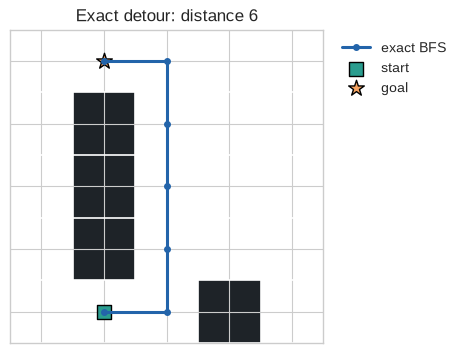

In [6]:
def plot_maze(axis, maze, *, paths=(), labels=(), title=""):
    image = np.ones((maze.size, maze.size, 3))
    image[maze.walls.numpy()] = np.array([0.12, 0.14, 0.16])
    axis.imshow(image, interpolation="nearest")
    colours = ["#2364aa", "#e76f51", "#2a9d8f"]
    for path, label, colour in zip(paths, labels, colours):
        if path:
            rows = [cell[0] for cell in path]
            columns = [cell[1] for cell in path]
            axis.plot(columns, rows, marker="o", linewidth=2.2, markersize=4, label=label, color=colour)
    axis.scatter([maze.start[1]], [maze.start[0]], s=110, marker="s", color="#2a9d8f", edgecolor="black", label="start")
    axis.scatter([maze.goal[1]], [maze.goal[0]], s=140, marker="*", color="#f4a261", edgecolor="black", label="goal")
    axis.set_xticks(range(maze.size)); axis.set_yticks(range(maze.size))
    axis.set_xticks(np.arange(-0.5, maze.size, 1), minor=True)
    axis.set_yticks(np.arange(-0.5, maze.size, 1), minor=True)
    axis.grid(which="minor", color="white", linewidth=1.2)
    axis.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
    axis.set_title(title)

preview_maze = generate_maze(19, require_detour=True)
figure, axis = plt.subplots(figsize=(4.5, 4.5), constrained_layout=True)
plot_maze(axis, preview_maze, paths=(preview_maze.path,), labels=("exact BFS",), title=f"Exact detour: distance {preview_maze.distance}")
axis.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

### Exercise 3: Tokenize the Entire Maze State

> **Difficulty:** 2/5 &nbsp; | &nbsp; **Importance:** 5/5 &nbsp; | &nbsp; **Time:** 15 minutes

Serialize `[BOS, SIZE, padded row-major grid, QUERY]`. Mark the current and goal cells in the grid itself so the query token can causally attend to the complete state.

<details>
<summary>Expected output</summary>

```text
All tests in `test_tokenize_maze_state` passed!
```

</details>

<details>
<summary>Help - getting started</summary>

Pad smaller mazes to 7 by 7 with wall tokens. Grid token position `2 + 7*row + column` must remain stable across sizes.

</details>

<details>
<summary>Common bugs</summary>

- padding with OPEN;
- moving QUERY before the grid;
- flattening column-major;
- overwriting CURRENT_GOAL incorrectly.

</details>

<details>
<summary>Interpretation</summary>

Stable token geometry lets a positional embedding refer to a physical cell. The causal query is the only position read by the action head.

</details>

<details>
<summary>Solution</summary>

```python
def tokenize_maze_state(
    maze: Maze,
    current: tuple[int, int],
    *,
    max_size: int = MAX_MAZE_SIZE,
) -> Tensor:
    """Serialize a maze state as a fixed-length causal token sequence."""

    if not (0 <= current[0] < maze.size and 0 <= current[1] < maze.size):
        raise ValueError("current lies outside the maze")
    if bool(maze.walls[current]):
        raise ValueError("current must be an open cell")
    size_token = {5: SIZE_5, 6: SIZE_6, 7: SIZE_7}.get(maze.size)
    if size_token is None:
        raise ValueError("this course vocabulary supports maze sizes 5, 6, and 7")
    grid_tokens: list[int] = []
    for row in range(max_size):
        for column in range(max_size):
            if row >= maze.size or column >= maze.size or bool(maze.walls[row, column]):
                token = WALL
            else:
                token = OPEN
            if (row, column) == maze.goal:
                token = GOAL
            if (row, column) == current:
                token = CURRENT_GOAL if current == maze.goal else CURRENT
            grid_tokens.append(token)
    return t.tensor([BOS, size_token, *grid_tokens, QUERY], dtype=t.long)
```

</details>

In [7]:
def tokenize_maze_state(
    maze: Maze,
    current: tuple[int, int],
    *,
    max_size: int = MAX_MAZE_SIZE,
) -> Tensor:
    """Serialize a maze state as a fixed-length causal token sequence."""

    if not (0 <= current[0] < maze.size and 0 <= current[1] < maze.size):
        raise ValueError("current lies outside the maze")
    if bool(maze.walls[current]):
        raise ValueError("current must be an open cell")
    size_token = {5: SIZE_5, 6: SIZE_6, 7: SIZE_7}.get(maze.size)
    if size_token is None:
        raise ValueError("this course vocabulary supports maze sizes 5, 6, and 7")
    grid_tokens: list[int] = []
    for row in range(max_size):
        for column in range(max_size):
            if row >= maze.size or column >= maze.size or bool(maze.walls[row, column]):
                token = WALL
            else:
                token = OPEN
            if (row, column) == maze.goal:
                token = GOAL
            if (row, column) == current:
                token = CURRENT_GOAL if current == maze.goal else CURRENT
            grid_tokens.append(token)
    return t.tensor([BOS, size_token, *grid_tokens, QUERY], dtype=t.long)

In [8]:
tests.test_tokenize_maze_state(tokenize_maze_state)

All tests in `test_tokenize_maze_state` passed!


### Exercise 4: Turn BFS Into Dense Policy Supervision

> **Difficulty:** 3/5 &nbsp; | &nbsp; **Importance:** 5/5 &nbsp; | &nbsp; **Time:** 20 minutes

For every reachable non-goal cell, select the first legal neighbor whose exact distance is one smaller. Store
distance and local legal-degree labels for evaluation only. Also record whether the wall-blind template move
is itself shortest. Two optimal moves with different tie-breaking rules must not become a false detour
example.

<details>
<summary>Expected output</summary>

```text
All tests in `test_build_state_dataset_bfs_policy` passed!
```

</details>

<details>
<summary>Help - getting started</summary>

Compute one reverse distance map per maze. Iterate over every open cell, not only the canonical route, so recovery states are in the training distribution.

</details>

<details>
<summary>Common bugs</summary>

- supervising only route states;
- using Manhattan distance through walls;
- leaking distance/local legal-degree labels into the token sequence.

</details>

<details>
<summary>Interpretation</summary>

Dense dynamic-programming supervision fixes a real distribution-shift problem: one rollout mistake should not move the policy into an entirely unseen state type.

</details>

<details>
<summary>Solution</summary>

```python
def template_action(current: tuple[int, int], goal: tuple[int, int]) -> int:
    """Axis-first action which ignores walls."""

    if current[1] < goal[1]:
        return 1
    if current[1] > goal[1]:
        return 3
    if current[0] < goal[0]:
        return 2
    return 0


def build_state_dataset(mazes: tuple[Maze, ...]) -> MazeDataset:
    """Create an exact shortest-action example at every reachable non-goal cell."""

    tokens: list[Tensor] = []
    actions: list[int] = []
    distances: list[int] = []
    legal_degrees: list[int] = []
    states: list[StateExample] = []
    for maze_id, maze in enumerate(mazes):
        distance_grid = distance_map(maze.walls, maze.goal)
        for row in range(maze.size):
            for column in range(maze.size):
                current = (row, column)
                distance = int(distance_grid[current])
                if distance <= 0:
                    continue
                downhill = [
                    neighbor
                    for neighbor in legal_neighbors(maze.walls, current)
                    if int(distance_grid[neighbor]) == distance - 1
                ]
                if not downhill:
                    raise AssertionError("reachable non-goal cell has no BFS-downhill neighbor")
                next_cell = downhill[0]
                action = action_between(current, next_cell)
                legal_degree = len(legal_neighbors(maze.walls, current))
                delta_row, delta_column = ACTION_DELTAS[template_action(current, maze.goal)]
                template_next = (row + delta_row, column + delta_column)
                template_is_shortest = (
                    template_next in legal_neighbors(maze.walls, current)
                    and int(distance_grid[template_next]) == distance - 1
                )
                tokens.append(tokenize_maze_state(maze, current))
                actions.append(action)
                distances.append(distance)
                legal_degrees.append(legal_degree)
                states.append(
                    StateExample(
                        maze_id=maze_id,
                        current=current,
                        goal=maze.goal,
                        action=action,
                        distance=distance,
                        legal_degree=legal_degree,
                        template_is_shortest=template_is_shortest,
                    )
                )
    return MazeDataset(
        tokens=t.stack(tokens),
        actions=t.tensor(actions),
        distances=t.tensor(distances),
        legal_degrees=t.tensor(legal_degrees) - 1,
        states=tuple(states),
    )
```

</details>

In [9]:
def template_action(current: tuple[int, int], goal: tuple[int, int]) -> int:
    """Axis-first action which ignores walls."""

    if current[1] < goal[1]:
        return 1
    if current[1] > goal[1]:
        return 3
    if current[0] < goal[0]:
        return 2
    return 0

def build_state_dataset(mazes: tuple[Maze, ...]) -> MazeDataset:
    """Create an exact shortest-action example at every reachable non-goal cell."""

    tokens: list[Tensor] = []
    actions: list[int] = []
    distances: list[int] = []
    legal_degrees: list[int] = []
    states: list[StateExample] = []
    for maze_id, maze in enumerate(mazes):
        distance_grid = distance_map(maze.walls, maze.goal)
        for row in range(maze.size):
            for column in range(maze.size):
                current = (row, column)
                distance = int(distance_grid[current])
                if distance <= 0:
                    continue
                downhill = [
                    neighbor
                    for neighbor in legal_neighbors(maze.walls, current)
                    if int(distance_grid[neighbor]) == distance - 1
                ]
                if not downhill:
                    raise AssertionError("reachable non-goal cell has no BFS-downhill neighbor")
                next_cell = downhill[0]
                action = action_between(current, next_cell)
                legal_degree = len(legal_neighbors(maze.walls, current))
                delta_row, delta_column = ACTION_DELTAS[template_action(current, maze.goal)]
                template_next = (row + delta_row, column + delta_column)
                template_is_shortest = (
                    template_next in legal_neighbors(maze.walls, current)
                    and int(distance_grid[template_next]) == distance - 1
                )
                tokens.append(tokenize_maze_state(maze, current))
                actions.append(action)
                distances.append(distance)
                legal_degrees.append(legal_degree)
                states.append(
                    StateExample(
                        maze_id=maze_id,
                        current=current,
                        goal=maze.goal,
                        action=action,
                        distance=distance,
                        legal_degree=legal_degree,
                        template_is_shortest=template_is_shortest,
                    )
                )
    return MazeDataset(
        tokens=t.stack(tokens),
        actions=t.tensor(actions),
        distances=t.tensor(distances),
        legal_degrees=t.tensor(legal_degrees) - 1,
        states=tuple(states),
    )

In [10]:
tests.test_build_state_dataset_bfs_policy(build_state_dataset)
tests.test_detour_labels_exclude_equally_short_ties(build_state_dataset)

All tests in `test_build_state_dataset_bfs_policy` passed!
All tests in `test_detour_labels_exclude_equally_short_ties` passed!


### Exercise 5: Implement Causal Attention and an Inspectable Block

> **Difficulty:** 4/5 &nbsp; | &nbsp; **Importance:** 5/5 &nbsp; | &nbsp; **Time:** 30 minutes

Implement multi-head self-attention with an explicit upper-triangular mask. Return attention patterns and per-head values, then cache residual, attention, and MLP contributions in each block.

<details>
<summary>Expected output</summary>

```text
All tests in `test_attention_is_causal` passed!
```

</details>

<details>
<summary>Help - getting started</summary>

Reshape QKV to `[batch, heads, sequence, head_dim]`; set strictly future scores to negative infinity before softmax.

</details>

<details>
<summary>Common bugs</summary>

- masking the diagonal;
- applying softmax before the mask;
- transposing head and sequence axes;
- caching tensors after they have been overwritten.

</details>

<details>
<summary>Interpretation</summary>

The causality test changes future tokens and demands bitwise-near-identical earlier outputs. A triangular-looking heatmap alone is weaker evidence.

</details>

<details>
<summary>Solution</summary>

```python
class CausalSelfAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int) -> None:
        super().__init__()
        if d_model % n_heads:
            raise ValueError("d_model must be divisible by n_heads")
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.output = nn.Linear(d_model, d_model)

    def forward(self, x: Tensor) -> tuple[Tensor, Tensor, Tensor]:
        batch, sequence, width = x.shape
        qkv = self.qkv(x).view(batch, sequence, 3, self.n_heads, self.head_dim)
        query, key, value = qkv.unbind(dim=2)
        query, key, value = (item.transpose(1, 2) for item in (query, key, value))
        scores = query @ key.transpose(-1, -2) / math.sqrt(self.head_dim)
        causal_mask = t.triu(
            t.ones(sequence, sequence, dtype=t.bool, device=x.device), diagonal=1
        )
        attention = scores.masked_fill(causal_mask, -t.inf).softmax(dim=-1)
        head_values = attention @ value
        joined = head_values.transpose(1, 2).contiguous().view(batch, sequence, width)
        return self.output(joined), attention, head_values


class TransformerBlock(nn.Module):
    def __init__(self, d_model: int, n_heads: int, d_mlp: int) -> None:
        super().__init__()
        self.norm_1 = nn.LayerNorm(d_model)
        self.attention = CausalSelfAttention(d_model, n_heads)
        self.norm_2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, d_mlp),
            nn.GELU(),
            nn.Linear(d_mlp, d_model),
        )

    def forward(self, x: Tensor) -> tuple[Tensor, dict[str, Tensor]]:
        residual_pre = x
        attention_output, pattern, head_values = self.attention(self.norm_1(x))
        x = x + attention_output
        mlp_output = self.mlp(self.norm_2(x))
        x = x + mlp_output
        return x, {
            "resid_pre": residual_pre,
            "attn_out": attention_output,
            "mlp_out": mlp_output,
            "resid_post": x,
            "pattern": pattern,
            "head_values": head_values,
        }
```

</details>

In [11]:
class CausalSelfAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int) -> None:
        super().__init__()
        if d_model % n_heads:
            raise ValueError("d_model must be divisible by n_heads")
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.output = nn.Linear(d_model, d_model)

    def forward(self, x: Tensor) -> tuple[Tensor, Tensor, Tensor]:
        batch, sequence, width = x.shape
        qkv = self.qkv(x).view(batch, sequence, 3, self.n_heads, self.head_dim)
        query, key, value = qkv.unbind(dim=2)
        query, key, value = (item.transpose(1, 2) for item in (query, key, value))
        scores = query @ key.transpose(-1, -2) / math.sqrt(self.head_dim)
        causal_mask = t.triu(
            t.ones(sequence, sequence, dtype=t.bool, device=x.device), diagonal=1
        )
        attention = scores.masked_fill(causal_mask, -t.inf).softmax(dim=-1)
        head_values = attention @ value
        joined = head_values.transpose(1, 2).contiguous().view(batch, sequence, width)
        return self.output(joined), attention, head_values

class TransformerBlock(nn.Module):
    def __init__(self, d_model: int, n_heads: int, d_mlp: int) -> None:
        super().__init__()
        self.norm_1 = nn.LayerNorm(d_model)
        self.attention = CausalSelfAttention(d_model, n_heads)
        self.norm_2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, d_mlp),
            nn.GELU(),
            nn.Linear(d_mlp, d_model),
        )

    def forward(self, x: Tensor) -> tuple[Tensor, dict[str, Tensor]]:
        residual_pre = x
        attention_output, pattern, head_values = self.attention(self.norm_1(x))
        x = x + attention_output
        mlp_output = self.mlp(self.norm_2(x))
        x = x + mlp_output
        return x, {
            "resid_pre": residual_pre,
            "attn_out": attention_output,
            "mlp_out": mlp_output,
            "resid_post": x,
            "pattern": pattern,
            "head_values": head_values,
        }

In [12]:
tests.test_attention_is_causal(CausalSelfAttention)

All tests in `test_attention_is_causal` passed!


### Exercise 6: Assemble the Decoder and Residual Cache

> **Difficulty:** 4/5 &nbsp; | &nbsp; **Importance:** 5/5 &nbsp; | &nbsp; **Time:** 25 minutes

Add token/position embeddings, causal blocks, final normalization, and a four-action head at QUERY. Support replacing one layer/position residual with an externally supplied vector.

<details>
<summary>Expected output</summary>

```text
All tests in `test_model_cache_and_residual_patch` passed!
```

</details>

<details>
<summary>Help - getting started</summary>

Apply the patch after the selected block and before the next block. Updating the cached `resid_post` keeps cache semantics honest.

</details>

<details>
<summary>Common bugs</summary>

- unembedding every grid position instead of QUERY;
- adding patches rather than replacing them;
- patching after final logits;
- returning detached training logits.

</details>

<details>
<summary>Interpretation</summary>

Replacing the final query residual with another run's residual must exactly reproduce that run's logits. This is the local oracle for the patching machinery, not the scientific result.

</details>

<details>
<summary>Solution</summary>

```python
class TinyMazeTransformer(nn.Module):
    """Decoder-only transformer with explicit layer/position activation cache."""

    def __init__(
        self,
        *,
        d_model: int = 64,
        n_layers: int = 3,
        n_heads: int = 4,
        d_mlp: int = 128,
    ) -> None:
        super().__init__()
        self.d_model = d_model
        self.n_layers = n_layers
        self.token_embedding = nn.Embedding(VOCAB_SIZE, d_model)
        self.position_embedding = nn.Parameter(t.randn(SEQUENCE_LENGTH, d_model) * 0.02)
        self.blocks = nn.ModuleList(
            [TransformerBlock(d_model, n_heads, d_mlp) for _ in range(n_layers)]
        )
        self.final_norm = nn.LayerNorm(d_model)
        self.action_head = nn.Linear(d_model, len(ACTION_NAMES))

    def forward(
        self,
        tokens: Tensor,
        *,
        return_cache: bool = False,
        residual_patch: tuple[int, int, Tensor] | None = None,
    ) -> Tensor | tuple[Tensor, dict[str, Any]]:
        if tokens.shape[-1] != SEQUENCE_LENGTH:
            raise ValueError(f"expected sequence length {SEQUENCE_LENGTH}")
        x = self.token_embedding(tokens) + self.position_embedding[None]
        cache: dict[str, Any] = {"embed": x, "blocks": []}
        for layer, block in enumerate(self.blocks):
            x, block_cache = block(x)
            if residual_patch is not None and residual_patch[0] == layer:
                _, position, replacement = residual_patch
                x = x.clone()
                x[:, position] = replacement
                block_cache["resid_post"] = x
            cache["blocks"].append(block_cache)
        logits = self.action_head(self.final_norm(x[:, QUERY_POSITION]))
        if return_cache:
            cache["final"] = x
            return logits, cache
        return logits
```

</details>

In [13]:
class TinyMazeTransformer(nn.Module):
    """Decoder-only transformer with explicit layer/position activation cache."""

    def __init__(
        self,
        *,
        d_model: int = 64,
        n_layers: int = 3,
        n_heads: int = 4,
        d_mlp: int = 128,
    ) -> None:
        super().__init__()
        self.d_model = d_model
        self.n_layers = n_layers
        self.token_embedding = nn.Embedding(VOCAB_SIZE, d_model)
        self.position_embedding = nn.Parameter(t.randn(SEQUENCE_LENGTH, d_model) * 0.02)
        self.blocks = nn.ModuleList(
            [TransformerBlock(d_model, n_heads, d_mlp) for _ in range(n_layers)]
        )
        self.final_norm = nn.LayerNorm(d_model)
        self.action_head = nn.Linear(d_model, len(ACTION_NAMES))

    def forward(
        self,
        tokens: Tensor,
        *,
        return_cache: bool = False,
        residual_patch: tuple[int, int, Tensor] | None = None,
    ) -> Tensor | tuple[Tensor, dict[str, Any]]:
        if tokens.shape[-1] != SEQUENCE_LENGTH:
            raise ValueError(f"expected sequence length {SEQUENCE_LENGTH}")
        x = self.token_embedding(tokens) + self.position_embedding[None]
        cache: dict[str, Any] = {"embed": x, "blocks": []}
        for layer, block in enumerate(self.blocks):
            x, block_cache = block(x)
            if residual_patch is not None and residual_patch[0] == layer:
                _, position, replacement = residual_patch
                x = x.clone()
                x[:, position] = replacement
                block_cache["resid_post"] = x
            cache["blocks"].append(block_cache)
        logits = self.action_head(self.final_norm(x[:, QUERY_POSITION]))
        if return_cache:
            cache["final"] = x
            return logits, cache
        return logits

In [14]:
tests.test_model_cache_and_residual_patch(TinyMazeTransformer)

All tests in `test_model_cache_and_residual_patch` passed!


### Exercise 7: Train and Preserve Checkpoints

> **Difficulty:** 4/5 &nbsp; | &nbsp; **Importance:** 5/5 &nbsp; | &nbsp; **Time:** 30 minutes

Train with cross-entropy on exact next actions. Record train loss and independent-layout accuracy every epoch, and clone CPU state dictionaries at early, middle, and final checkpoints.

<details>
<summary>Expected output</summary>

```text
All tests in `test_training_and_checkpointing` passed!
```

</details>

<details>
<summary>Help - getting started</summary>

Use a seeded permutation each epoch. A checkpoint needs `detach().cpu().clone()`; a shallow state-dict reference mutates as training continues.

</details>

<details>
<summary>Common bugs</summary>

- evaluating on training layouts;
- saving views of live parameters;
- omitting optimizer zeroing;
- reporting only final loss.

</details>

<details>
<summary>Interpretation</summary>

Like the grokking chapter, checkpoint curves let you ask when capabilities and representations appear, rather than treating the final network as timeless.

</details>

<details>
<summary>Solution</summary>

```python
@t.no_grad()
def action_accuracy(model: TinyMazeTransformer, dataset: MazeDataset, batch_size: int = 256) -> float:
    model.eval()
    correct = 0
    for start in range(0, len(dataset.tokens), batch_size):
        tokens = dataset.tokens[start : start + batch_size].to(next(model.parameters()).device)
        labels = dataset.actions[start : start + batch_size].to(tokens.device)
        correct += int(model(tokens).argmax(-1).eq(labels).sum().item())
    return correct / len(dataset.tokens)


def train_maze_transformer(
    train_data: MazeDataset,
    heldout_data: MazeDataset,
    *,
    device: str | t.device = "cpu",
    seed: int = 0,
    epochs: int = 12,
    batch_size: int = 128,
    learning_rate: float = 2e-3,
    d_model: int = 64,
    n_layers: int = 3,
) -> tuple[TinyMazeTransformer, TrainingResult]:
    """Train a real maze policy and retain immutable state-dict checkpoints."""

    device = t.device(device)
    if device.type == "cuda":
        if os.environ.get("CUBLAS_WORKSPACE_CONFIG") not in {":4096:8", ":16:8"}:
            raise RuntimeError("Set CUBLAS_WORKSPACE_CONFIG=:4096:8 before starting the CUDA process.")
        t.use_deterministic_algorithms(True)
        t.set_float32_matmul_precision("highest")
    t.manual_seed(seed)
    model = TinyMazeTransformer(d_model=d_model, n_layers=n_layers).to(device)
    optimizer = t.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-3)
    generator = t.Generator().manual_seed(seed + 1)
    train_loss: list[float] = []
    heldout_accuracy: list[float] = []
    checkpoint_epochs: list[int] = []
    checkpoints: list[dict[str, Tensor]] = []

    for epoch in range(epochs):
        model.train()
        ordering = t.randperm(len(train_data.tokens), generator=generator)
        losses: list[float] = []
        for indices in ordering.split(batch_size):
            tokens = train_data.tokens[indices].to(device)
            labels = train_data.actions[indices].to(device)
            loss = F.cross_entropy(model(tokens), labels)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            t.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(loss.detach().item())
        train_loss.append(sum(losses) / len(losses))
        heldout_accuracy.append(action_accuracy(model, heldout_data))
        if epoch in {0, epochs // 2, epochs - 1}:
            checkpoint_epochs.append(epoch + 1)
            checkpoints.append(
                {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
            )
    return model, TrainingResult(
        train_loss=tuple(train_loss),
        heldout_action_accuracy=tuple(heldout_accuracy),
        checkpoint_epochs=tuple(checkpoint_epochs),
        checkpoints=tuple(checkpoints),
    )
```

</details>

In [15]:
@t.no_grad()
def action_accuracy(model: TinyMazeTransformer, dataset: MazeDataset, batch_size: int = 256) -> float:
    model.eval()
    correct = 0
    for start in range(0, len(dataset.tokens), batch_size):
        tokens = dataset.tokens[start : start + batch_size].to(next(model.parameters()).device)
        labels = dataset.actions[start : start + batch_size].to(tokens.device)
        correct += int(model(tokens).argmax(-1).eq(labels).sum().item())
    return correct / len(dataset.tokens)

def train_maze_transformer(
    train_data: MazeDataset,
    heldout_data: MazeDataset,
    *,
    device: str | t.device = "cpu",
    seed: int = 0,
    epochs: int = 12,
    batch_size: int = 128,
    learning_rate: float = 2e-3,
    d_model: int = 64,
    n_layers: int = 3,
) -> tuple[TinyMazeTransformer, TrainingResult]:
    """Train a real maze policy and retain immutable state-dict checkpoints."""

    device = t.device(device)
    if device.type == "cuda":
        if os.environ.get("CUBLAS_WORKSPACE_CONFIG") not in {":4096:8", ":16:8"}:
            raise RuntimeError("Set CUBLAS_WORKSPACE_CONFIG=:4096:8 before starting the CUDA process.")
        t.use_deterministic_algorithms(True)
        t.set_float32_matmul_precision("highest")
    t.manual_seed(seed)
    model = TinyMazeTransformer(d_model=d_model, n_layers=n_layers).to(device)
    optimizer = t.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-3)
    generator = t.Generator().manual_seed(seed + 1)
    train_loss: list[float] = []
    heldout_accuracy: list[float] = []
    checkpoint_epochs: list[int] = []
    checkpoints: list[dict[str, Tensor]] = []

    for epoch in range(epochs):
        model.train()
        ordering = t.randperm(len(train_data.tokens), generator=generator)
        losses: list[float] = []
        for indices in ordering.split(batch_size):
            tokens = train_data.tokens[indices].to(device)
            labels = train_data.actions[indices].to(device)
            loss = F.cross_entropy(model(tokens), labels)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            t.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(loss.detach().item())
        train_loss.append(sum(losses) / len(losses))
        heldout_accuracy.append(action_accuracy(model, heldout_data))
        if epoch in {0, epochs // 2, epochs - 1}:
            checkpoint_epochs.append(epoch + 1)
            checkpoints.append(
                {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
            )
    return model, TrainingResult(
        train_loss=tuple(train_loss),
        heldout_action_accuracy=tuple(heldout_accuracy),
        checkpoint_epochs=tuple(checkpoint_epochs),
        checkpoints=tuple(checkpoints),
    )

In [16]:
tests.test_training_and_checkpointing(train_maze_transformer)

All tests in `test_training_and_checkpointing` passed!


### Exercise 8: Roll Out Paths and Score Three Different Claims

> **Difficulty:** 3/5 &nbsp; | &nbsp; **Importance:** 5/5 &nbsp; | &nbsp; **Time:** 25 minutes

Autoregress by updating the current-cell token after each action. Evaluate raw argmax and legal-action-constrained decoding, plus a wall-blind axis-first template baseline.

<details>
<summary>Expected output</summary>

```text
All tests in `test_template_rollout_scores_validity_separately` passed!
```

</details>

<details>
<summary>Help - getting started</summary>

Terminate on illegal moves, loops, goal reach, or the step budget. Optimal means reached goal and action count equals exact BFS distance.

</details>

<details>
<summary>Common bugs</summary>

- treating every legal prefix as a valid solution;
- counting goal reach as optimality;
- silently masking illegal raw outputs;
- allowing loops until timeout without marking failure.

</details>

<details>
<summary>Interpretation</summary>

Constrained decoding measures whether model rankings contain a usable policy when environment legality is supplied. Raw illegal rate remains an independent limitation.

</details>

<details>
<summary>Solution</summary>

```python
def apply_action(
    walls: Tensor,
    current: tuple[int, int],
    action: int,
) -> tuple[int, int] | None:
    if not 0 <= action < len(ACTION_DELTAS):
        raise ValueError("action must be one of 0, 1, 2, 3")
    delta_row, delta_column = ACTION_DELTAS[action]
    candidate = (current[0] + delta_row, current[1] + delta_column)
    return candidate if candidate in legal_neighbors(walls, current) else None


@t.no_grad()
def rollout_model(
    model: TinyMazeTransformer,
    maze: Maze,
    *,
    max_steps: int | None = None,
    constrain_legal: bool = False,
) -> Rollout:
    """Autoregress by repeatedly querying the model on its updated current cell."""

    model.eval()
    device = next(model.parameters()).device
    max_steps = 2 * maze.size**2 if max_steps is None else max_steps
    if max_steps < 0:
        raise ValueError("max_steps must be nonnegative")
    cells = [maze.start]
    actions: list[int] = []
    seen = {maze.start}
    legal = True
    for _ in range(max_steps):
        current = cells[-1]
        if current == maze.goal:
            break
        tokens = tokenize_maze_state(maze, current).unsqueeze(0).to(device)
        logits = model(tokens)[0]
        if constrain_legal:
            legal_actions = [
                action_index
                for action_index in range(len(ACTION_NAMES))
                if apply_action(maze.walls, current, action_index) is not None
            ]
            action = max(legal_actions, key=lambda index: float(logits[index]))
        else:
            action = int(logits.argmax().item())
        actions.append(action)
        next_cell = apply_action(maze.walls, current, action)
        if next_cell is None:
            legal = False
            break
        cells.append(next_cell)
        if next_cell in seen and next_cell != maze.goal:
            break
        seen.add(next_cell)
    reached = cells[-1] == maze.goal
    return Rollout(
        cells=tuple(cells),
        actions=tuple(actions),
        legal=legal,
        reached_goal=reached,
        optimal=reached and len(actions) == maze.distance,
    )


def template_action(current: tuple[int, int], goal: tuple[int, int]) -> int:
    """Axis-first action which ignores walls."""

    if current[1] < goal[1]:
        return 1
    if current[1] > goal[1]:
        return 3
    if current[0] < goal[0]:
        return 2
    return 0


def template_rollout(maze: Maze) -> Rollout:
    """Axis-first Manhattan policy which ignores walls until it collides."""

    current = maze.start
    cells = [current]
    actions: list[int] = []
    seen = {current}
    legal = True
    for _ in range(2 * maze.size**2):
        if current == maze.goal:
            break
        if current[1] < maze.goal[1]:
            action = 1
        elif current[1] > maze.goal[1]:
            action = 3
        elif current[0] < maze.goal[0]:
            action = 2
        else:
            action = 0
        actions.append(action)
        next_cell = apply_action(maze.walls, current, action)
        if next_cell is None:
            legal = False
            break
        current = next_cell
        cells.append(current)
        if current in seen and current != maze.goal:
            break
        seen.add(current)
    reached = current == maze.goal
    return Rollout(tuple(cells), tuple(actions), legal, reached, reached and len(actions) == maze.distance)


def score_rollouts(rollouts: tuple[Rollout, ...], mazes: tuple[Maze, ...]) -> RolloutMetrics:
    """Recompute legality, reach, and optimality from actions and actual walls.

    Stored boolean flags are convenient display metadata, not scoring evidence.
    Cell traces must agree with the independently replayed actions.
    """
    if len(rollouts) != len(mazes) or not rollouts:
        raise ValueError("rollouts and mazes must be nonempty and aligned")
    legal_flags, reached_flags, optimal_flags, excess = [], [], [], []
    for rollout, maze in zip(rollouts, mazes):
        replay = [maze.start]
        legal = True
        for step, action in enumerate(rollout.actions):
            if replay[-1] == maze.goal:
                raise ValueError("a rollout must stop when it reaches the goal")
            next_cell = apply_action(maze.walls, replay[-1], action)
            if next_cell is None:
                legal = False
                if step != len(rollout.actions) - 1:
                    raise ValueError("an illegal move must terminate the rollout")
                break
            replay.append(next_cell)
        if tuple(replay) != rollout.cells:
            raise ValueError("cell trace does not match replayed actions")
        shortest = bfs_shortest_path(maze.walls, maze.start, maze.goal)
        reached = legal and replay[-1] == maze.goal
        distance = len(shortest) - 1 if shortest is not None else math.inf
        optimal = reached and len(rollout.actions) == distance
        legal_flags.append(legal)
        reached_flags.append(reached)
        optimal_flags.append(optimal)
        if reached:
            excess.append(len(rollout.actions) - distance)
    return RolloutMetrics(
        legal_path_rate=sum(legal_flags) / len(rollouts),
        goal_reach_rate=sum(reached_flags) / len(rollouts),
        optimal_path_rate=sum(optimal_flags) / len(rollouts),
        mean_excess_steps=sum(excess) / max(1, len(excess)),
        illegal_move_rate=sum(not legal for legal in legal_flags) / len(rollouts),
    )
```

</details>

In [17]:
def apply_action(
    walls: Tensor,
    current: tuple[int, int],
    action: int,
) -> tuple[int, int] | None:
    if not 0 <= action < len(ACTION_DELTAS):
        raise ValueError("action must be one of 0, 1, 2, 3")
    delta_row, delta_column = ACTION_DELTAS[action]
    candidate = (current[0] + delta_row, current[1] + delta_column)
    return candidate if candidate in legal_neighbors(walls, current) else None

@t.no_grad()
def rollout_model(
    model: TinyMazeTransformer,
    maze: Maze,
    *,
    max_steps: int | None = None,
    constrain_legal: bool = False,
) -> Rollout:
    """Autoregress by repeatedly querying the model on its updated current cell."""

    model.eval()
    device = next(model.parameters()).device
    max_steps = 2 * maze.size**2 if max_steps is None else max_steps
    if max_steps < 0:
        raise ValueError("max_steps must be nonnegative")
    cells = [maze.start]
    actions: list[int] = []
    seen = {maze.start}
    legal = True
    for _ in range(max_steps):
        current = cells[-1]
        if current == maze.goal:
            break
        tokens = tokenize_maze_state(maze, current).unsqueeze(0).to(device)
        logits = model(tokens)[0]
        if constrain_legal:
            legal_actions = [
                action_index
                for action_index in range(len(ACTION_NAMES))
                if apply_action(maze.walls, current, action_index) is not None
            ]
            action = max(legal_actions, key=lambda index: float(logits[index]))
        else:
            action = int(logits.argmax().item())
        actions.append(action)
        next_cell = apply_action(maze.walls, current, action)
        if next_cell is None:
            legal = False
            break
        cells.append(next_cell)
        if next_cell in seen and next_cell != maze.goal:
            break
        seen.add(next_cell)
    reached = cells[-1] == maze.goal
    return Rollout(
        cells=tuple(cells),
        actions=tuple(actions),
        legal=legal,
        reached_goal=reached,
        optimal=reached and len(actions) == maze.distance,
    )

def template_action(current: tuple[int, int], goal: tuple[int, int]) -> int:
    """Axis-first action which ignores walls."""

    if current[1] < goal[1]:
        return 1
    if current[1] > goal[1]:
        return 3
    if current[0] < goal[0]:
        return 2
    return 0

def template_rollout(maze: Maze) -> Rollout:
    """Axis-first Manhattan policy which ignores walls until it collides."""

    current = maze.start
    cells = [current]
    actions: list[int] = []
    seen = {current}
    legal = True
    for _ in range(2 * maze.size**2):
        if current == maze.goal:
            break
        if current[1] < maze.goal[1]:
            action = 1
        elif current[1] > maze.goal[1]:
            action = 3
        elif current[0] < maze.goal[0]:
            action = 2
        else:
            action = 0
        actions.append(action)
        next_cell = apply_action(maze.walls, current, action)
        if next_cell is None:
            legal = False
            break
        current = next_cell
        cells.append(current)
        if current in seen and current != maze.goal:
            break
        seen.add(current)
    reached = current == maze.goal
    return Rollout(tuple(cells), tuple(actions), legal, reached, reached and len(actions) == maze.distance)

def score_rollouts(rollouts: tuple[Rollout, ...], mazes: tuple[Maze, ...]) -> RolloutMetrics:
    """Recompute legality, reach, and optimality from actions and actual walls.

    Stored boolean flags are convenient display metadata, not scoring evidence.
    Cell traces must agree with the independently replayed actions.
    """
    if len(rollouts) != len(mazes) or not rollouts:
        raise ValueError("rollouts and mazes must be nonempty and aligned")
    legal_flags, reached_flags, optimal_flags, excess = [], [], [], []
    for rollout, maze in zip(rollouts, mazes):
        replay = [maze.start]
        legal = True
        for step, action in enumerate(rollout.actions):
            if replay[-1] == maze.goal:
                raise ValueError("a rollout must stop when it reaches the goal")
            next_cell = apply_action(maze.walls, replay[-1], action)
            if next_cell is None:
                legal = False
                if step != len(rollout.actions) - 1:
                    raise ValueError("an illegal move must terminate the rollout")
                break
            replay.append(next_cell)
        if tuple(replay) != rollout.cells:
            raise ValueError("cell trace does not match replayed actions")
        shortest = bfs_shortest_path(maze.walls, maze.start, maze.goal)
        reached = legal and replay[-1] == maze.goal
        distance = len(shortest) - 1 if shortest is not None else math.inf
        optimal = reached and len(rollout.actions) == distance
        legal_flags.append(legal)
        reached_flags.append(reached)
        optimal_flags.append(optimal)
        if reached:
            excess.append(len(rollout.actions) - distance)
    return RolloutMetrics(
        legal_path_rate=sum(legal_flags) / len(rollouts),
        goal_reach_rate=sum(reached_flags) / len(rollouts),
        optimal_path_rate=sum(optimal_flags) / len(rollouts),
        mean_excess_steps=sum(excess) / max(1, len(excess)),
        illegal_move_rate=sum(not legal for legal in legal_flags) / len(rollouts),
    )

In [18]:
tests.test_template_rollout_scores_validity_separately(template_rollout, score_rollouts)
tests.test_rollout_scores_replay_actions(score_rollouts)
tests.test_raw_and_constrained_rollout_use_learner_policy(rollout_model)

All tests in `test_template_rollout_scores_validity_separately` passed!
All tests in `test_rollout_scores_replay_actions` passed!
All tests in `test_raw_and_constrained_rollout_use_learner_policy` passed!


### Exercise 9: Decode Distance, Legal Degree, and Next Action Across Layers

> **Difficulty:** 4/5 &nbsp; | &nbsp; **Importance:** 5/5 &nbsp; | &nbsp; **Time:** 30 minutes

Cache QUERY representations before any block and after every block. Fit held-out ridge probes for near/medium/far BFS distance, legal-neighbor count, and exact next action.

<details>
<summary>Expected output</summary>

```text
All tests in `test_ridge_probe_toy_oracle` passed!
```

</details>

<details>
<summary>Help - getting started</summary>

Fit preprocessing on train features only. Use independent held-out layouts and compare distance probes against separately shuffled train and test labels.

</details>

<details>
<summary>Common bugs</summary>

- fitting and testing on states from the same mazes;
- leaking held-out normalization statistics;
- reporting training accuracy;
- treating a probe as causal evidence.

</details>

<details>
<summary>Interpretation</summary>

A layer sweep asks *when* state becomes linearly available. Randomized labels test finite-sample probe capacity, but intervention is still needed to test use.

</details>

<details>
<summary>Solution</summary>

```python
@t.no_grad()
def extract_layer_features(
    model: TinyMazeTransformer,
    dataset: MazeDataset,
    *,
    max_examples: int = 1_200,
    batch_size: int = 256,
) -> Tensor:
    """Return query-position features as [layers+1, examples, d_model]."""

    model.eval()
    device = next(model.parameters()).device
    layer_chunks: list[list[Tensor]] = [[] for _ in range(model.n_layers + 1)]
    tokens = dataset.tokens[:max_examples]
    for batch in tokens.split(batch_size):
        _, cache = model(batch.to(device), return_cache=True)
        layer_chunks[0].append(cache["embed"][:, QUERY_POSITION].cpu())
        for layer, block_cache in enumerate(cache["blocks"]):
            layer_chunks[layer + 1].append(block_cache["resid_post"][:, QUERY_POSITION].cpu())
    return t.stack([t.cat(chunks) for chunks in layer_chunks])


def ridge_probe_accuracy(
    train_features: Tensor,
    train_labels: Tensor,
    test_features: Tensor,
    test_labels: Tensor,
    *,
    n_classes: int,
    ridge: float = 1e-2,
) -> float:
    """Closed-form standardized multiclass ridge probe."""

    mean = train_features.float().mean(0, keepdim=True)
    scale = train_features.float().std(0, keepdim=True).clamp_min(1e-5)
    train = (train_features.float() - mean) / scale
    test = (test_features.float() - mean) / scale
    train = t.cat((train, t.ones(len(train), 1)), dim=1)
    test = t.cat((test, t.ones(len(test), 1)), dim=1)
    targets = F.one_hot(train_labels, n_classes).float()
    identity = t.eye(train.shape[1])
    identity[-1, -1] = 0
    weights = t.linalg.solve(train.T @ train + ridge * identity, train.T @ targets)
    return (test @ weights).argmax(-1).eq(test_labels).float().mean().item()


def layerwise_probe_metrics(
    model: TinyMazeTransformer,
    train_data: MazeDataset,
    heldout_data: MazeDataset,
    *,
    seed: int = 0,
) -> ProbeResult:
    train_features = extract_layer_features(model, train_data)
    heldout_features = extract_layer_features(model, heldout_data)
    train_count = train_features.shape[1]
    heldout_count = heldout_features.shape[1]
    distance_boundaries = t.tensor([2, 4])
    train_distance = t.bucketize(
        train_data.distances[:train_count], distance_boundaries
    )
    heldout_distance = t.bucketize(
        heldout_data.distances[:heldout_count], distance_boundaries
    )
    train_legal_degree = train_data.legal_degrees[:train_count]
    heldout_legal_degree = heldout_data.legal_degrees[:heldout_count]
    train_action = train_data.actions[:train_count]
    heldout_action = heldout_data.actions[:heldout_count]
    generator = t.Generator().manual_seed(seed)
    shuffled_train = train_distance[t.randperm(train_count, generator=generator)]
    manhattan_distances = t.tensor([
        abs(state.current[0] - state.goal[0]) + abs(state.current[1] - state.goal[1])
        for state in heldout_data.states[:heldout_count]
    ])
    manhattan_accuracy = float(
        t.bucketize(manhattan_distances, distance_boundaries).eq(heldout_distance).float().mean()
    )

    distance_scores: list[float] = []
    legal_degree_scores: list[float] = []
    action_scores: list[float] = []
    random_scores: list[float] = []
    for train_layer, test_layer in zip(train_features, heldout_features):
        distance_scores.append(
            ridge_probe_accuracy(
                train_layer, train_distance, test_layer, heldout_distance, n_classes=3
            )
        )
        legal_degree_scores.append(
            ridge_probe_accuracy(
                train_layer, train_legal_degree, test_layer, heldout_legal_degree, n_classes=4
            )
        )
        action_scores.append(
            ridge_probe_accuracy(train_layer, train_action, test_layer, heldout_action, n_classes=4)
        )
        random_scores.append(
            ridge_probe_accuracy(
                train_layer, shuffled_train, test_layer, heldout_distance, n_classes=3
            )
        )
    return ProbeResult(
        distance_accuracy=tuple(distance_scores),
        legal_degree_accuracy=tuple(legal_degree_scores),
        action_accuracy=tuple(action_scores),
        random_label_distance_accuracy=tuple(random_scores),
        manhattan_distance_accuracy=manhattan_accuracy,
    )
```

</details>

In [19]:
@t.no_grad()
def extract_layer_features(
    model: TinyMazeTransformer,
    dataset: MazeDataset,
    *,
    max_examples: int = 1_200,
    batch_size: int = 256,
) -> Tensor:
    """Return query-position features as [layers+1, examples, d_model]."""

    model.eval()
    device = next(model.parameters()).device
    layer_chunks: list[list[Tensor]] = [[] for _ in range(model.n_layers + 1)]
    tokens = dataset.tokens[:max_examples]
    for batch in tokens.split(batch_size):
        _, cache = model(batch.to(device), return_cache=True)
        layer_chunks[0].append(cache["embed"][:, QUERY_POSITION].cpu())
        for layer, block_cache in enumerate(cache["blocks"]):
            layer_chunks[layer + 1].append(block_cache["resid_post"][:, QUERY_POSITION].cpu())
    return t.stack([t.cat(chunks) for chunks in layer_chunks])

def ridge_probe_accuracy(
    train_features: Tensor,
    train_labels: Tensor,
    test_features: Tensor,
    test_labels: Tensor,
    *,
    n_classes: int,
    ridge: float = 1e-2,
) -> float:
    """Closed-form standardized multiclass ridge probe."""

    mean = train_features.float().mean(0, keepdim=True)
    scale = train_features.float().std(0, keepdim=True).clamp_min(1e-5)
    train = (train_features.float() - mean) / scale
    test = (test_features.float() - mean) / scale
    train = t.cat((train, t.ones(len(train), 1)), dim=1)
    test = t.cat((test, t.ones(len(test), 1)), dim=1)
    targets = F.one_hot(train_labels, n_classes).float()
    identity = t.eye(train.shape[1])
    identity[-1, -1] = 0
    weights = t.linalg.solve(train.T @ train + ridge * identity, train.T @ targets)
    return (test @ weights).argmax(-1).eq(test_labels).float().mean().item()

def layerwise_probe_metrics(
    model: TinyMazeTransformer,
    train_data: MazeDataset,
    heldout_data: MazeDataset,
    *,
    seed: int = 0,
) -> ProbeResult:
    train_features = extract_layer_features(model, train_data)
    heldout_features = extract_layer_features(model, heldout_data)
    train_count = train_features.shape[1]
    heldout_count = heldout_features.shape[1]
    distance_boundaries = t.tensor([2, 4])
    train_distance = t.bucketize(
        train_data.distances[:train_count], distance_boundaries
    )
    heldout_distance = t.bucketize(
        heldout_data.distances[:heldout_count], distance_boundaries
    )
    train_legal_degree = train_data.legal_degrees[:train_count]
    heldout_legal_degree = heldout_data.legal_degrees[:heldout_count]
    train_action = train_data.actions[:train_count]
    heldout_action = heldout_data.actions[:heldout_count]
    generator = t.Generator().manual_seed(seed)
    shuffled_train = train_distance[t.randperm(train_count, generator=generator)]
    manhattan_distances = t.tensor([
        abs(state.current[0] - state.goal[0]) + abs(state.current[1] - state.goal[1])
        for state in heldout_data.states[:heldout_count]
    ])
    manhattan_accuracy = float(
        t.bucketize(manhattan_distances, distance_boundaries).eq(heldout_distance).float().mean()
    )

    distance_scores: list[float] = []
    legal_degree_scores: list[float] = []
    action_scores: list[float] = []
    random_scores: list[float] = []
    for train_layer, test_layer in zip(train_features, heldout_features):
        distance_scores.append(
            ridge_probe_accuracy(
                train_layer, train_distance, test_layer, heldout_distance, n_classes=3
            )
        )
        legal_degree_scores.append(
            ridge_probe_accuracy(
                train_layer, train_legal_degree, test_layer, heldout_legal_degree, n_classes=4
            )
        )
        action_scores.append(
            ridge_probe_accuracy(train_layer, train_action, test_layer, heldout_action, n_classes=4)
        )
        random_scores.append(
            ridge_probe_accuracy(
                train_layer, shuffled_train, test_layer, heldout_distance, n_classes=3
            )
        )
    return ProbeResult(
        distance_accuracy=tuple(distance_scores),
        legal_degree_accuracy=tuple(legal_degree_scores),
        action_accuracy=tuple(action_scores),
        random_label_distance_accuracy=tuple(random_scores),
        manhattan_distance_accuracy=manhattan_accuracy,
    )

In [20]:
tests.test_ridge_probe_toy_oracle(ridge_probe_accuracy)

All tests in `test_ridge_probe_toy_oracle` passed!


### Exercise 10: Break the Maze-Action Relationship

> **Difficulty:** 3/5 &nbsp; | &nbsp; **Importance:** 5/5 &nbsp; | &nbsp; **Time:** 20 minutes

Shuffle wall layouts across examples while preserving each current and goal marker. Evaluate all states and those where the wall-blind move is blocked or not shortest.

<details>
<summary>Expected output</summary>

```text
detour accuracy on intact mazes > shuffled-maze detour accuracy
```

</details>

<details>
<summary>Help - getting started</summary>

Remove CURRENT/GOAL markers from donor grids before overlaying the original markers. Keep labels and split fixed.

</details>

<details>
<summary>Common bugs</summary>

- shuffling labels instead of walls;
- leaving donor start/goal markers;
- evaluating an easier random subset rather than detour states.

</details>

<details>
<summary>Interpretation</summary>

The gap can be modest because many shortest actions point toward the goal regardless of walls. Here detour states require that the template's next move be blocked or fail to reduce exact BFS distance. Disagreement with the canonical action alone is insufficient: multiple next actions can be optimal.

</details>

<details>
<summary>Solution</summary>

```python
def shuffled_maze_accuracy(
    model: TinyMazeTransformer,
    dataset: MazeDataset,
    *,
    seed: int = 0,
) -> float:
    """Shuffle wall layouts while retaining each example's current/goal markers."""

    generator = t.Generator().manual_seed(seed)
    source_order = t.randperm(len(dataset.tokens), generator=generator)
    corrupted = dataset.tokens.clone()
    grid_slice = slice(2, 2 + MAX_MAZE_SIZE**2)
    source_grid = dataset.tokens[source_order, grid_slice].clone()
    source_grid[(source_grid == CURRENT) | (source_grid == GOAL) | (source_grid == CURRENT_GOAL)] = OPEN
    original_grid = dataset.tokens[:, grid_slice]
    source_grid[original_grid == CURRENT] = CURRENT
    source_grid[original_grid == GOAL] = GOAL
    source_grid[original_grid == CURRENT_GOAL] = CURRENT_GOAL
    corrupted[:, grid_slice] = source_grid
    corrupt_dataset = MazeDataset(
        tokens=corrupted,
        actions=dataset.actions,
        distances=dataset.distances,
        legal_degrees=dataset.legal_degrees,
        states=dataset.states,
    )
    return action_accuracy(model, corrupt_dataset)


@t.no_grad()
def detour_action_accuracy(
    model: TinyMazeTransformer,
    dataset: MazeDataset,
    *,
    shuffled_mazes: bool = False,
    seed: int = 0,
) -> float:
    """Evaluate states where the wall-blind move is blocked or not BFS-downhill.

    A different tie break between equally short moves is not a detour.
    """

    indices = t.tensor(
        [
            index
            for index, state in enumerate(dataset.states)
            if not state.template_is_shortest
        ]
    )
    if indices.numel() == 0:
        raise ValueError("dataset has no states where the template is not shortest")
    tokens = dataset.tokens.clone()
    if shuffled_mazes:
        generator = t.Generator().manual_seed(seed)
        order = t.randperm(len(tokens), generator=generator)
        grid_slice = slice(2, 2 + MAX_MAZE_SIZE**2)
        source = tokens[order, grid_slice].clone()
        source[(source == CURRENT) | (source == GOAL) | (source == CURRENT_GOAL)] = OPEN
        original = tokens[:, grid_slice]
        source[original == CURRENT] = CURRENT
        source[original == GOAL] = GOAL
        source[original == CURRENT_GOAL] = CURRENT_GOAL
        tokens[:, grid_slice] = source
    subset = MazeDataset(
        tokens=tokens[indices],
        actions=dataset.actions[indices],
        distances=dataset.distances[indices],
        legal_degrees=dataset.legal_degrees[indices],
        states=tuple(dataset.states[index] for index in indices.tolist()),
    )
    return action_accuracy(model, subset)
```

</details>

In [21]:
def shuffled_maze_accuracy(
    model: TinyMazeTransformer,
    dataset: MazeDataset,
    *,
    seed: int = 0,
) -> float:
    """Shuffle wall layouts while retaining each example's current/goal markers."""

    generator = t.Generator().manual_seed(seed)
    source_order = t.randperm(len(dataset.tokens), generator=generator)
    corrupted = dataset.tokens.clone()
    grid_slice = slice(2, 2 + MAX_MAZE_SIZE**2)
    source_grid = dataset.tokens[source_order, grid_slice].clone()
    source_grid[(source_grid == CURRENT) | (source_grid == GOAL) | (source_grid == CURRENT_GOAL)] = OPEN
    original_grid = dataset.tokens[:, grid_slice]
    source_grid[original_grid == CURRENT] = CURRENT
    source_grid[original_grid == GOAL] = GOAL
    source_grid[original_grid == CURRENT_GOAL] = CURRENT_GOAL
    corrupted[:, grid_slice] = source_grid
    corrupt_dataset = MazeDataset(
        tokens=corrupted,
        actions=dataset.actions,
        distances=dataset.distances,
        legal_degrees=dataset.legal_degrees,
        states=dataset.states,
    )
    return action_accuracy(model, corrupt_dataset)

@t.no_grad()
def detour_action_accuracy(
    model: TinyMazeTransformer,
    dataset: MazeDataset,
    *,
    shuffled_mazes: bool = False,
    seed: int = 0,
) -> float:
    """Evaluate states where the wall-blind move is blocked or not BFS-downhill.

    A different tie break between equally short moves is not a detour.
    """

    indices = t.tensor(
        [
            index
            for index, state in enumerate(dataset.states)
            if not state.template_is_shortest
        ]
    )
    if indices.numel() == 0:
        raise ValueError("dataset has no states where the template is not shortest")
    tokens = dataset.tokens.clone()
    if shuffled_mazes:
        generator = t.Generator().manual_seed(seed)
        order = t.randperm(len(tokens), generator=generator)
        grid_slice = slice(2, 2 + MAX_MAZE_SIZE**2)
        source = tokens[order, grid_slice].clone()
        source[(source == CURRENT) | (source == GOAL) | (source == CURRENT_GOAL)] = OPEN
        original = tokens[:, grid_slice]
        source[original == CURRENT] = CURRENT
        source[original == GOAL] = GOAL
        source[original == CURRENT_GOAL] = CURRENT_GOAL
        tokens[:, grid_slice] = source
    subset = MazeDataset(
        tokens=tokens[indices],
        actions=dataset.actions[indices],
        distances=dataset.distances[indices],
        legal_degrees=dataset.legal_degrees[indices],
        states=tuple(dataset.states[index] for index in indices.tolist()),
    )
    return action_accuracy(model, subset)

In [22]:
tests.test_shuffle_preserves_markers_and_input(shuffled_maze_accuracy)

All tests in `test_shuffle_preserves_markers_and_input` passed!


### Exercise 11: Patch Counterfactual Route State

> **Difficulty:** 5/5 &nbsp; | &nbsp; **Importance:** 5/5 &nbsp; | &nbsp; **Time:** 40 minutes

Choose two correctly solved states from the same maze that require different next actions. Patch the donor run's residual into the recipient across layers and positions. Compare a middle-layer query patch against wrong-position, random-direction, unrelated-state, and same-action other-maze donors.

<details>
<summary>Expected output</summary>

```text
final query replacement reproduces donor logits exactly
middle-layer specificity is measured, not assumed
```

</details>

<details>
<summary>Help - getting started</summary>

Normalize the corrupt-vs-clean action margin so clean is 0 and corrupt is 1. Exclude the final-layer exact-recovery cell when making a mechanistic claim.

</details>

<details>
<summary>Common bugs</summary>

- patching mazes with the same target action;
- dividing by a near-zero clean/corrupt gap;
- comparing additive targeted patches to replacement controls;
- claiming final-query recovery as a discovered circuit.

</details>

<details>
<summary>Interpretation</summary>

The intervention asks whether downstream action computation uses information in this residual. A same-action
donor from another maze tests the stronger route-specific interpretation. Compare its effect with targeted
patches on exactly the same eligible pairs, and display the pair count. Similar effects support transferable
action information without identifying a search algorithm.

</details>

<details>
<summary>Solution</summary>

```python
def _state_tokens(maze: Maze, cell: tuple[int, int], device: t.device) -> Tensor:
    return tokenize_maze_state(maze, cell).unsqueeze(0).to(device)


def _action_margin(logits: Tensor, target_action: int, clean_action: int) -> float:
    return float((logits[0, target_action] - logits[0, clean_action]).item())


@t.no_grad()
def residual_patching_heatmap(
    model: TinyMazeTransformer,
    maze: Maze,
    clean_index: int,
    corrupt_index: int,
) -> Tensor:
    """Patch every layer/position and normalize recovery of the corrupt action margin."""

    model.eval()
    device = next(model.parameters()).device
    clean_action = action_between(maze.path[clean_index], maze.path[clean_index + 1])
    corrupt_action = action_between(maze.path[corrupt_index], maze.path[corrupt_index + 1])
    if clean_action == corrupt_action:
        raise ValueError("clean and corrupt route states must require different actions")
    clean_tokens = _state_tokens(maze, maze.path[clean_index], device)
    corrupt_tokens = _state_tokens(maze, maze.path[corrupt_index], device)
    clean_logits, _ = model(clean_tokens, return_cache=True)
    corrupt_logits, corrupt_cache = model(corrupt_tokens, return_cache=True)
    clean_margin = _action_margin(clean_logits, corrupt_action, clean_action)
    corrupt_margin = _action_margin(corrupt_logits, corrupt_action, clean_action)
    denominator = corrupt_margin - clean_margin
    if abs(denominator) < 1e-5:
        raise ValueError("model does not distinguish the selected route states")
    heatmap = t.zeros(model.n_layers, SEQUENCE_LENGTH)
    for layer in range(model.n_layers):
        for position in range(SEQUENCE_LENGTH):
            replacement = corrupt_cache["blocks"][layer]["resid_post"][:, position]
            patched = model(
                clean_tokens,
                residual_patch=(layer, position, replacement),
            )
            patched_margin = _action_margin(patched, corrupt_action, clean_action)
            heatmap[layer, position] = (patched_margin - clean_margin) / denominator
    return heatmap


def _counterfactual_pairs(
    model: TinyMazeTransformer,
    mazes: tuple[Maze, ...],
    *,
    max_pairs: int = 24,
) -> list[tuple[Maze, int, int]]:
    pairs: list[tuple[Maze, int, int]] = []
    device = next(model.parameters()).device
    with t.no_grad():
        for maze in mazes:
            route_actions = [action_between(a, b) for a, b in zip(maze.path[:-1], maze.path[1:])]
            for first in range(len(route_actions)):
                for second in range(first + 1, len(route_actions)):
                    if route_actions[first] == route_actions[second]:
                        continue
                    first_prediction = int(model(_state_tokens(maze, maze.path[first], device)).argmax(-1))
                    second_prediction = int(model(_state_tokens(maze, maze.path[second], device)).argmax(-1))
                    if (
                        first_prediction == route_actions[first]
                        and second_prediction == route_actions[second]
                    ):
                        pairs.append((maze, first, second))
                        break
                if pairs and pairs[-1][0] is maze:
                    break
            if len(pairs) >= max_pairs:
                break
    return pairs


@t.no_grad()
def route_state_intervention_metrics(
    model: TinyMazeTransformer,
    mazes: tuple[Maze, ...],
    *,
    seed: int = 0,
) -> PatchingResult:
    """Compare targeted query patches with three matched replacement controls."""

    pairs = _counterfactual_pairs(model, mazes)
    if len(pairs) < 4:
        raise RuntimeError("not enough correctly solved counterfactual route-state pairs")
    device = next(model.parameters()).device
    layer = max(0, model.n_layers - 2)
    generator = t.Generator(device=device).manual_seed(seed)
    targeted: list[float] = []
    wrong_position: list[float] = []
    matched_random: list[float] = []
    unrelated: list[float] = []
    same_action: list[float] = []
    same_action_targeted: list[float] = []

    for pair_index, (maze, clean_index, corrupt_index) in enumerate(pairs):
        clean_action = action_between(maze.path[clean_index], maze.path[clean_index + 1])
        corrupt_action = action_between(maze.path[corrupt_index], maze.path[corrupt_index + 1])
        clean_tokens = _state_tokens(maze, maze.path[clean_index], device)
        corrupt_tokens = _state_tokens(maze, maze.path[corrupt_index], device)
        clean_logits, clean_cache = model(clean_tokens, return_cache=True)
        corrupt_logits, corrupt_cache = model(corrupt_tokens, return_cache=True)
        clean_margin = _action_margin(clean_logits, corrupt_action, clean_action)
        corrupt_margin = _action_margin(corrupt_logits, corrupt_action, clean_action)
        denominator = max(1e-5, corrupt_margin - clean_margin)
        clean_query = clean_cache["blocks"][layer]["resid_post"][:, QUERY_POSITION]
        corrupt_query = corrupt_cache["blocks"][layer]["resid_post"][:, QUERY_POSITION]

        patched_logits = model(clean_tokens, residual_patch=(layer, QUERY_POSITION, corrupt_query))
        targeted.append(
            (_action_margin(patched_logits, corrupt_action, clean_action) - clean_margin) / denominator
        )

        wrong_logits = model(clean_tokens, residual_patch=(layer, 2, corrupt_query))
        wrong_position.append(
            (_action_margin(wrong_logits, corrupt_action, clean_action) - clean_margin) / denominator
        )

        delta = corrupt_query - clean_query
        random_delta = t.randn(delta.shape, generator=generator, device=device)
        random_delta = F.normalize(random_delta, dim=-1) * delta.norm(dim=-1, keepdim=True)
        random_logits = model(
            clean_tokens,
            residual_patch=(layer, QUERY_POSITION, clean_query + random_delta),
        )
        matched_random.append(
            (_action_margin(random_logits, corrupt_action, clean_action) - clean_margin) / denominator
        )

        other_maze, _, other_corrupt_index = pairs[(pair_index + 1) % len(pairs)]
        other_tokens = _state_tokens(other_maze, other_maze.path[other_corrupt_index], device)
        _, other_cache = model(other_tokens, return_cache=True)
        other_query = other_cache["blocks"][layer]["resid_post"][:, QUERY_POSITION]
        unrelated_logits = model(
            clean_tokens,
            residual_patch=(layer, QUERY_POSITION, other_query),
        )
        unrelated.append(
            (_action_margin(unrelated_logits, corrupt_action, clean_action) - clean_margin)
            / denominator
        )

        # Does a donor with the same next action work without sharing this maze?
        donor = next((
            (candidate, second) for candidate, _, second in pairs
            if _maze_key(candidate) != _maze_key(maze)
            and action_between(candidate.path[second], candidate.path[second + 1]) == corrupt_action
        ), None)
        if donor is not None:
            donor_maze, donor_index = donor
            _, donor_cache = model(
                _state_tokens(donor_maze, donor_maze.path[donor_index], device), return_cache=True
            )
            donor_query = donor_cache["blocks"][layer]["resid_post"][:, QUERY_POSITION]
            donor_logits = model(clean_tokens, residual_patch=(layer, QUERY_POSITION, donor_query))
            same_action.append(
                (_action_margin(donor_logits, corrupt_action, clean_action) - clean_margin) / denominator
            )
            same_action_targeted.append(targeted[-1])

    first_maze, first_clean, first_corrupt = pairs[0]
    heatmap = residual_patching_heatmap(model, first_maze, first_clean, first_corrupt)
    if not same_action:
        raise RuntimeError("no same-action donors from different maze layouts are available")
    return PatchingResult(
        heatmap=heatmap,
        targeted_effect=float(t.tensor(targeted).median()),
        targeted_positive_fraction=float((t.tensor(targeted) > 0).float().mean()),
        wrong_position_effect=float(t.tensor(wrong_position).abs().median()),
        matched_norm_random_effect=float(t.tensor(matched_random).abs().median()),
        unrelated_route_effect=float(t.tensor(unrelated).median()),
        same_action_other_maze_effect=float(t.tensor(same_action).median()),
        same_action_targeted_effect=float(t.tensor(same_action_targeted).median()),
        same_action_pair_count=len(same_action),
        pair_count=len(pairs),
    )
```

</details>

In [23]:
def _state_tokens(maze: Maze, cell: tuple[int, int], device: t.device) -> Tensor:
    return tokenize_maze_state(maze, cell).unsqueeze(0).to(device)

def _action_margin(logits: Tensor, target_action: int, clean_action: int) -> float:
    return float((logits[0, target_action] - logits[0, clean_action]).item())

@t.no_grad()
def residual_patching_heatmap(
    model: TinyMazeTransformer,
    maze: Maze,
    clean_index: int,
    corrupt_index: int,
) -> Tensor:
    """Patch every layer/position and normalize recovery of the corrupt action margin."""

    model.eval()
    device = next(model.parameters()).device
    clean_action = action_between(maze.path[clean_index], maze.path[clean_index + 1])
    corrupt_action = action_between(maze.path[corrupt_index], maze.path[corrupt_index + 1])
    if clean_action == corrupt_action:
        raise ValueError("clean and corrupt route states must require different actions")
    clean_tokens = _state_tokens(maze, maze.path[clean_index], device)
    corrupt_tokens = _state_tokens(maze, maze.path[corrupt_index], device)
    clean_logits, _ = model(clean_tokens, return_cache=True)
    corrupt_logits, corrupt_cache = model(corrupt_tokens, return_cache=True)
    clean_margin = _action_margin(clean_logits, corrupt_action, clean_action)
    corrupt_margin = _action_margin(corrupt_logits, corrupt_action, clean_action)
    denominator = corrupt_margin - clean_margin
    if abs(denominator) < 1e-5:
        raise ValueError("model does not distinguish the selected route states")
    heatmap = t.zeros(model.n_layers, SEQUENCE_LENGTH)
    for layer in range(model.n_layers):
        for position in range(SEQUENCE_LENGTH):
            replacement = corrupt_cache["blocks"][layer]["resid_post"][:, position]
            patched = model(
                clean_tokens,
                residual_patch=(layer, position, replacement),
            )
            patched_margin = _action_margin(patched, corrupt_action, clean_action)
            heatmap[layer, position] = (patched_margin - clean_margin) / denominator
    return heatmap

def _counterfactual_pairs(
    model: TinyMazeTransformer,
    mazes: tuple[Maze, ...],
    *,
    max_pairs: int = 24,
) -> list[tuple[Maze, int, int]]:
    pairs: list[tuple[Maze, int, int]] = []
    device = next(model.parameters()).device
    with t.no_grad():
        for maze in mazes:
            route_actions = [action_between(a, b) for a, b in zip(maze.path[:-1], maze.path[1:])]
            for first in range(len(route_actions)):
                for second in range(first + 1, len(route_actions)):
                    if route_actions[first] == route_actions[second]:
                        continue
                    first_prediction = int(model(_state_tokens(maze, maze.path[first], device)).argmax(-1))
                    second_prediction = int(model(_state_tokens(maze, maze.path[second], device)).argmax(-1))
                    if (
                        first_prediction == route_actions[first]
                        and second_prediction == route_actions[second]
                    ):
                        pairs.append((maze, first, second))
                        break
                if pairs and pairs[-1][0] is maze:
                    break
            if len(pairs) >= max_pairs:
                break
    return pairs

@t.no_grad()
def route_state_intervention_metrics(
    model: TinyMazeTransformer,
    mazes: tuple[Maze, ...],
    *,
    seed: int = 0,
) -> PatchingResult:
    """Compare targeted query patches with three matched replacement controls."""

    pairs = _counterfactual_pairs(model, mazes)
    if len(pairs) < 4:
        raise RuntimeError("not enough correctly solved counterfactual route-state pairs")
    device = next(model.parameters()).device
    layer = max(0, model.n_layers - 2)
    generator = t.Generator(device=device).manual_seed(seed)
    targeted: list[float] = []
    wrong_position: list[float] = []
    matched_random: list[float] = []
    unrelated: list[float] = []
    same_action: list[float] = []
    same_action_targeted: list[float] = []

    for pair_index, (maze, clean_index, corrupt_index) in enumerate(pairs):
        clean_action = action_between(maze.path[clean_index], maze.path[clean_index + 1])
        corrupt_action = action_between(maze.path[corrupt_index], maze.path[corrupt_index + 1])
        clean_tokens = _state_tokens(maze, maze.path[clean_index], device)
        corrupt_tokens = _state_tokens(maze, maze.path[corrupt_index], device)
        clean_logits, clean_cache = model(clean_tokens, return_cache=True)
        corrupt_logits, corrupt_cache = model(corrupt_tokens, return_cache=True)
        clean_margin = _action_margin(clean_logits, corrupt_action, clean_action)
        corrupt_margin = _action_margin(corrupt_logits, corrupt_action, clean_action)
        denominator = max(1e-5, corrupt_margin - clean_margin)
        clean_query = clean_cache["blocks"][layer]["resid_post"][:, QUERY_POSITION]
        corrupt_query = corrupt_cache["blocks"][layer]["resid_post"][:, QUERY_POSITION]

        patched_logits = model(clean_tokens, residual_patch=(layer, QUERY_POSITION, corrupt_query))
        targeted.append(
            (_action_margin(patched_logits, corrupt_action, clean_action) - clean_margin) / denominator
        )

        wrong_logits = model(clean_tokens, residual_patch=(layer, 2, corrupt_query))
        wrong_position.append(
            (_action_margin(wrong_logits, corrupt_action, clean_action) - clean_margin) / denominator
        )

        delta = corrupt_query - clean_query
        random_delta = t.randn(delta.shape, generator=generator, device=device)
        random_delta = F.normalize(random_delta, dim=-1) * delta.norm(dim=-1, keepdim=True)
        random_logits = model(
            clean_tokens,
            residual_patch=(layer, QUERY_POSITION, clean_query + random_delta),
        )
        matched_random.append(
            (_action_margin(random_logits, corrupt_action, clean_action) - clean_margin) / denominator
        )

        other_maze, _, other_corrupt_index = pairs[(pair_index + 1) % len(pairs)]
        other_tokens = _state_tokens(other_maze, other_maze.path[other_corrupt_index], device)
        _, other_cache = model(other_tokens, return_cache=True)
        other_query = other_cache["blocks"][layer]["resid_post"][:, QUERY_POSITION]
        unrelated_logits = model(
            clean_tokens,
            residual_patch=(layer, QUERY_POSITION, other_query),
        )
        unrelated.append(
            (_action_margin(unrelated_logits, corrupt_action, clean_action) - clean_margin)
            / denominator
        )

        # Does a donor with the same next action work without sharing this maze?
        donor = next((
            (candidate, second) for candidate, _, second in pairs
            if _maze_key(candidate) != _maze_key(maze)
            and action_between(candidate.path[second], candidate.path[second + 1]) == corrupt_action
        ), None)
        if donor is not None:
            donor_maze, donor_index = donor
            _, donor_cache = model(
                _state_tokens(donor_maze, donor_maze.path[donor_index], device), return_cache=True
            )
            donor_query = donor_cache["blocks"][layer]["resid_post"][:, QUERY_POSITION]
            donor_logits = model(clean_tokens, residual_patch=(layer, QUERY_POSITION, donor_query))
            same_action.append(
                (_action_margin(donor_logits, corrupt_action, clean_action) - clean_margin) / denominator
            )
            same_action_targeted.append(targeted[-1])

    first_maze, first_clean, first_corrupt = pairs[0]
    heatmap = residual_patching_heatmap(model, first_maze, first_clean, first_corrupt)
    if not same_action:
        raise RuntimeError("no same-action donors from different maze layouts are available")
    return PatchingResult(
        heatmap=heatmap,
        targeted_effect=float(t.tensor(targeted).median()),
        targeted_positive_fraction=float((t.tensor(targeted) > 0).float().mean()),
        wrong_position_effect=float(t.tensor(wrong_position).abs().median()),
        matched_norm_random_effect=float(t.tensor(matched_random).abs().median()),
        unrelated_route_effect=float(t.tensor(unrelated).median()),
        same_action_other_maze_effect=float(t.tensor(same_action).median()),
        same_action_targeted_effect=float(t.tensor(same_action_targeted).median()),
        same_action_pair_count=len(same_action),
        pair_count=len(pairs),
    )

In [24]:
tests.test_residual_patching_heatmap_has_exact_final_recovery(residual_patching_heatmap)
tests.test_same_action_donor_exposes_action_only_state(route_state_intervention_metrics)

All tests in `test_residual_patching_heatmap_has_exact_final_recovery` passed!
All tests in `test_same_action_donor_exposes_action_only_state` passed!


### Exercise 12: Run the Complete Controlled Experiment

> **Difficulty:** 4/5 &nbsp; | &nbsp; **Importance:** 5/5 &nbsp; | &nbsp; **Time:** 20 minutes

Combine disjoint datasets, training, checkpoints, rollouts, probes, shuffled mazes, patch controls, and two OOD conditions. Fail loudly when any core claim misses its threshold.

<details>
<summary>Expected output</summary>

```text
held-out action >= 0.72; constrained goal reach >= 0.58; distance probe margin >= 0.25; targeted patch effect >= 0.15 and is positive on >= 85% of pairs
```

</details>

<details>
<summary>Help - getting started</summary>

Keep raw and constrained rollout metrics side by side. Record size-6 transfer even if it fails; it is an OOD diagnostic, not a release gate.

</details>

<details>
<summary>Common bugs</summary>

- selecting successful mazes before computing aggregate rates;
- hiding raw illegal moves;
- reusing training templates;
- averaging targeted and control effects together.

</details>

<details>
<summary>Interpretation</summary>

The experiment supports a narrow controlled claim: usable internal maze state and a causal route-state signal. It does not recover a complete planning algorithm from weights.

</details>

<details>
<summary>Solution</summary>

```python
def _rollout_suite(
    model: TinyMazeTransformer,
    mazes: tuple[Maze, ...],
    *,
    constrain_legal: bool,
) -> tuple[Rollout, ...]:
    return tuple(
        rollout_model(model, maze, constrain_legal=constrain_legal) for maze in mazes
    )


def run_signature_experiment(
    *,
    device: str | t.device = "cpu",
    seed: int = 0,
    train_maze_count: int = 420,
    heldout_maze_count: int = 100,
    epochs: int = 12,
    d_model: int = 64,
) -> ExperimentArtifacts:
    """Train, probe, intervene, and score paths on disjoint generated mazes."""

    device = t.device(device)
    if device.type == "cuda":
        t.cuda.reset_peak_memory_stats(device)
    train_mazes = generate_maze_collection(train_maze_count, seed=seed, require_detour_fraction=0.25)
    train_keys = {_maze_key(maze) for maze in train_mazes}
    heldout_mazes = generate_maze_collection(
        heldout_maze_count,
        seed=seed + 100_000,
        require_detour_fraction=0.5,
        excluded_keys=train_keys,
    )
    density_ood = generate_maze_collection(
        60,
        seed=seed + 200_000,
        obstacle_density=0.28,
        require_detour_fraction=0.5,
        excluded_keys=train_keys,
    )
    size_ood = generate_maze_collection(
        40,
        seed=seed + 300_000,
        size=6,
        obstacle_density=0.16,
        require_detour_fraction=0.25,
    )
    train_data = build_state_dataset(train_mazes)
    heldout_data = build_state_dataset(heldout_mazes)
    model, training = train_maze_transformer(
        train_data,
        heldout_data,
        device=device,
        seed=seed,
        epochs=epochs,
        d_model=d_model,
    )
    probes = layerwise_probe_metrics(model, train_data, heldout_data, seed=seed + 1)
    patching = route_state_intervention_metrics(model, heldout_mazes, seed=seed + 2)
    evaluation_mazes = heldout_mazes[:60]
    model_rollouts = _rollout_suite(model, evaluation_mazes, constrain_legal=True)
    raw_model_rollouts = _rollout_suite(model, evaluation_mazes, constrain_legal=False)
    template_rollouts = tuple(template_rollout(maze) for maze in evaluation_mazes)
    density_rollouts = _rollout_suite(
        model, density_ood[:40], constrain_legal=True
    )
    size_rollouts = _rollout_suite(model, size_ood[:30], constrain_legal=True)
    model_scores = score_rollouts(model_rollouts, evaluation_mazes)
    raw_model_scores = score_rollouts(raw_model_rollouts, evaluation_mazes)
    template_scores = score_rollouts(template_rollouts, evaluation_mazes)
    density_scores = score_rollouts(density_rollouts, density_ood[:40])
    size_scores = score_rollouts(size_rollouts, size_ood[:30])
    shuffled_accuracy = shuffled_maze_accuracy(model, heldout_data, seed=seed + 3)
    detour_accuracy = detour_action_accuracy(model, heldout_data)
    shuffled_detour_accuracy = detour_action_accuracy(
        model, heldout_data, shuffled_mazes=True, seed=seed + 3
    )
    final_action_accuracy = action_accuracy(model, heldout_data)
    template_overlap = len(train_keys & {_maze_key(maze) for maze in heldout_mazes})
    peak_vram_gb = 0.0
    if device.type == "cuda":
        peak_vram_gb = t.cuda.max_memory_allocated(device) / 2**30

    metrics: dict[str, float | int | bool] = {
        "heldout_action_accuracy": final_action_accuracy,
        "shuffled_maze_action_accuracy": shuffled_accuracy,
        "detour_action_accuracy": detour_accuracy,
        "shuffled_maze_detour_accuracy": shuffled_detour_accuracy,
        "detour_shuffled_maze_margin": detour_accuracy - shuffled_detour_accuracy,
        "legal_path_rate": model_scores.legal_path_rate,
        "goal_reach_rate": model_scores.goal_reach_rate,
        "optimal_path_rate": model_scores.optimal_path_rate,
        "mean_excess_steps": model_scores.mean_excess_steps,
        "illegal_move_rate": model_scores.illegal_move_rate,
        "raw_goal_reach_rate": raw_model_scores.goal_reach_rate,
        "raw_optimal_path_rate": raw_model_scores.optimal_path_rate,
        "raw_illegal_move_rate": raw_model_scores.illegal_move_rate,
        "template_goal_reach_rate": template_scores.goal_reach_rate,
        "template_optimal_path_rate": template_scores.optimal_path_rate,
        "template_illegal_move_rate": template_scores.illegal_move_rate,
        "goal_reach_margin_over_template": (
            model_scores.goal_reach_rate - template_scores.goal_reach_rate
        ),
        "density_ood_goal_reach_rate": density_scores.goal_reach_rate,
        "density_ood_optimal_path_rate": density_scores.optimal_path_rate,
        "size_ood_goal_reach_rate": size_scores.goal_reach_rate,
        "size_ood_optimal_path_rate": size_scores.optimal_path_rate,
        "best_distance_probe_accuracy": max(probes.distance_accuracy),
        "best_legal_degree_probe_accuracy": max(probes.legal_degree_accuracy),
        "best_action_probe_accuracy": max(probes.action_accuracy),
        "random_label_distance_probe_accuracy": max(probes.random_label_distance_accuracy),
        "manhattan_distance_accuracy": probes.manhattan_distance_accuracy,
        "distance_probe_random_label_margin": (
            max(probes.distance_accuracy) - max(probes.random_label_distance_accuracy)
        ),
        "targeted_patch_effect": patching.targeted_effect,
        "targeted_patch_positive_fraction": patching.targeted_positive_fraction,
        "wrong_position_patch_effect": patching.wrong_position_effect,
        "matched_norm_random_patch_effect": patching.matched_norm_random_effect,
        "unrelated_route_patch_effect": patching.unrelated_route_effect,
        "same_action_other_maze_patch_effect": patching.same_action_other_maze_effect,
        "same_action_targeted_patch_effect": patching.same_action_targeted_effect,
        "same_action_patch_pair_count": patching.same_action_pair_count,
        "targeted_patch_wrong_position_margin": (
            patching.targeted_effect - patching.wrong_position_effect
        ),
        "targeted_patch_matched_random_margin": (
            patching.targeted_effect - patching.matched_norm_random_effect
        ),
        "patch_pair_count": patching.pair_count,
        "train_heldout_template_overlap": template_overlap,
        "peak_vram_gb": peak_vram_gb,
    }
    return ExperimentArtifacts(
        model=model,
        train_mazes=train_mazes,
        heldout_mazes=heldout_mazes,
        density_ood_mazes=density_ood,
        size_ood_mazes=size_ood,
        training=training,
        probes=probes,
        patching=patching,
        model_rollouts=model_rollouts,
        bfs_paths=tuple(maze.path for maze in evaluation_mazes),
        metrics=metrics,
    )


def validate_experiment(
    artifacts: ExperimentArtifacts,
    *,
    require_cuda: bool = False,
    max_vram_gb: float = 24.0,
) -> None:
    metrics = artifacts.metrics
    if require_cuda:
        assert next(artifacts.model.parameters()).is_cuda, (
            "GPU verification requires CUDA; CPU fallback is forbidden."
        )
    checks = {
        "zero train/heldout overlap": metrics["train_heldout_template_overlap"] == 0,
        "heldout action >= 0.72": metrics["heldout_action_accuracy"] >= 0.72,
        "true-detour shuffled-wall margin >= 0.04": metrics["detour_action_accuracy"] >= metrics["shuffled_maze_detour_accuracy"] + 0.04,
        "legal paths >= 0.99": metrics["legal_path_rate"] >= 0.99,
        "goal reach >= 0.58": metrics["goal_reach_rate"] >= 0.58,
        "optimal paths >= 0.48": metrics["optimal_path_rate"] >= 0.48,
        "goal reach template margin >= 0.08": metrics["goal_reach_rate"] >= metrics["template_goal_reach_rate"] + 0.08,
        "distance probe >= 0.62": metrics["best_distance_probe_accuracy"] >= 0.62,
        "distance probe random-label margin >= 0.25": metrics["best_distance_probe_accuracy"] >= metrics["random_label_distance_probe_accuracy"] + 0.25,
        "targeted patch >= 0.15": metrics["targeted_patch_effect"] >= 0.15,
        "positive patch pairs >= 0.85": metrics["targeted_patch_positive_fraction"] >= 0.85,
        "patch wrong-position margin >= 0.10": metrics["targeted_patch_effect"] >= metrics["wrong_position_patch_effect"] + 0.10,
        "patch random-direction margin >= 0.10": metrics["targeted_patch_effect"] >= metrics["matched_norm_random_patch_effect"] + 0.10,
        "VRAM within declared budget": metrics["peak_vram_gb"] <= max_vram_gb,
    }
    failed = [name for name, passed in checks.items() if not passed]
    assert not failed, "Failed numerical checks: " + "; ".join(failed)
```

</details>

In [25]:
def _rollout_suite(
    model: TinyMazeTransformer,
    mazes: tuple[Maze, ...],
    *,
    constrain_legal: bool,
) -> tuple[Rollout, ...]:
    return tuple(
        rollout_model(model, maze, constrain_legal=constrain_legal) for maze in mazes
    )

def run_signature_experiment(
    *,
    device: str | t.device = "cpu",
    seed: int = 0,
    train_maze_count: int = 420,
    heldout_maze_count: int = 100,
    epochs: int = 12,
    d_model: int = 64,
) -> ExperimentArtifacts:
    """Train, probe, intervene, and score paths on disjoint generated mazes."""

    device = t.device(device)
    if device.type == "cuda":
        t.cuda.reset_peak_memory_stats(device)
    train_mazes = generate_maze_collection(train_maze_count, seed=seed, require_detour_fraction=0.25)
    train_keys = {_maze_key(maze) for maze in train_mazes}
    heldout_mazes = generate_maze_collection(
        heldout_maze_count,
        seed=seed + 100_000,
        require_detour_fraction=0.5,
        excluded_keys=train_keys,
    )
    density_ood = generate_maze_collection(
        60,
        seed=seed + 200_000,
        obstacle_density=0.28,
        require_detour_fraction=0.5,
        excluded_keys=train_keys,
    )
    size_ood = generate_maze_collection(
        40,
        seed=seed + 300_000,
        size=6,
        obstacle_density=0.16,
        require_detour_fraction=0.25,
    )
    train_data = build_state_dataset(train_mazes)
    heldout_data = build_state_dataset(heldout_mazes)
    model, training = train_maze_transformer(
        train_data,
        heldout_data,
        device=device,
        seed=seed,
        epochs=epochs,
        d_model=d_model,
    )
    probes = layerwise_probe_metrics(model, train_data, heldout_data, seed=seed + 1)
    patching = route_state_intervention_metrics(model, heldout_mazes, seed=seed + 2)
    evaluation_mazes = heldout_mazes[:60]
    model_rollouts = _rollout_suite(model, evaluation_mazes, constrain_legal=True)
    raw_model_rollouts = _rollout_suite(model, evaluation_mazes, constrain_legal=False)
    template_rollouts = tuple(template_rollout(maze) for maze in evaluation_mazes)
    density_rollouts = _rollout_suite(
        model, density_ood[:40], constrain_legal=True
    )
    size_rollouts = _rollout_suite(model, size_ood[:30], constrain_legal=True)
    model_scores = score_rollouts(model_rollouts, evaluation_mazes)
    raw_model_scores = score_rollouts(raw_model_rollouts, evaluation_mazes)
    template_scores = score_rollouts(template_rollouts, evaluation_mazes)
    density_scores = score_rollouts(density_rollouts, density_ood[:40])
    size_scores = score_rollouts(size_rollouts, size_ood[:30])
    shuffled_accuracy = shuffled_maze_accuracy(model, heldout_data, seed=seed + 3)
    detour_accuracy = detour_action_accuracy(model, heldout_data)
    shuffled_detour_accuracy = detour_action_accuracy(
        model, heldout_data, shuffled_mazes=True, seed=seed + 3
    )
    final_action_accuracy = action_accuracy(model, heldout_data)
    template_overlap = len(train_keys & {_maze_key(maze) for maze in heldout_mazes})
    peak_vram_gb = 0.0
    if device.type == "cuda":
        peak_vram_gb = t.cuda.max_memory_allocated(device) / 2**30

    metrics: dict[str, float | int | bool] = {
        "heldout_action_accuracy": final_action_accuracy,
        "shuffled_maze_action_accuracy": shuffled_accuracy,
        "detour_action_accuracy": detour_accuracy,
        "shuffled_maze_detour_accuracy": shuffled_detour_accuracy,
        "detour_shuffled_maze_margin": detour_accuracy - shuffled_detour_accuracy,
        "legal_path_rate": model_scores.legal_path_rate,
        "goal_reach_rate": model_scores.goal_reach_rate,
        "optimal_path_rate": model_scores.optimal_path_rate,
        "mean_excess_steps": model_scores.mean_excess_steps,
        "illegal_move_rate": model_scores.illegal_move_rate,
        "raw_goal_reach_rate": raw_model_scores.goal_reach_rate,
        "raw_optimal_path_rate": raw_model_scores.optimal_path_rate,
        "raw_illegal_move_rate": raw_model_scores.illegal_move_rate,
        "template_goal_reach_rate": template_scores.goal_reach_rate,
        "template_optimal_path_rate": template_scores.optimal_path_rate,
        "template_illegal_move_rate": template_scores.illegal_move_rate,
        "goal_reach_margin_over_template": (
            model_scores.goal_reach_rate - template_scores.goal_reach_rate
        ),
        "density_ood_goal_reach_rate": density_scores.goal_reach_rate,
        "density_ood_optimal_path_rate": density_scores.optimal_path_rate,
        "size_ood_goal_reach_rate": size_scores.goal_reach_rate,
        "size_ood_optimal_path_rate": size_scores.optimal_path_rate,
        "best_distance_probe_accuracy": max(probes.distance_accuracy),
        "best_legal_degree_probe_accuracy": max(probes.legal_degree_accuracy),
        "best_action_probe_accuracy": max(probes.action_accuracy),
        "random_label_distance_probe_accuracy": max(probes.random_label_distance_accuracy),
        "manhattan_distance_accuracy": probes.manhattan_distance_accuracy,
        "distance_probe_random_label_margin": (
            max(probes.distance_accuracy) - max(probes.random_label_distance_accuracy)
        ),
        "targeted_patch_effect": patching.targeted_effect,
        "targeted_patch_positive_fraction": patching.targeted_positive_fraction,
        "wrong_position_patch_effect": patching.wrong_position_effect,
        "matched_norm_random_patch_effect": patching.matched_norm_random_effect,
        "unrelated_route_patch_effect": patching.unrelated_route_effect,
        "same_action_other_maze_patch_effect": patching.same_action_other_maze_effect,
        "same_action_targeted_patch_effect": patching.same_action_targeted_effect,
        "same_action_patch_pair_count": patching.same_action_pair_count,
        "targeted_patch_wrong_position_margin": (
            patching.targeted_effect - patching.wrong_position_effect
        ),
        "targeted_patch_matched_random_margin": (
            patching.targeted_effect - patching.matched_norm_random_effect
        ),
        "patch_pair_count": patching.pair_count,
        "train_heldout_template_overlap": template_overlap,
        "peak_vram_gb": peak_vram_gb,
    }
    return ExperimentArtifacts(
        model=model,
        train_mazes=train_mazes,
        heldout_mazes=heldout_mazes,
        density_ood_mazes=density_ood,
        size_ood_mazes=size_ood,
        training=training,
        probes=probes,
        patching=patching,
        model_rollouts=model_rollouts,
        bfs_paths=tuple(maze.path for maze in evaluation_mazes),
        metrics=metrics,
    )

def validate_experiment(
    artifacts: ExperimentArtifacts,
    *,
    require_cuda: bool = False,
    max_vram_gb: float = 24.0,
) -> None:
    metrics = artifacts.metrics
    if require_cuda:
        assert next(artifacts.model.parameters()).is_cuda, (
            "GPU verification requires CUDA; CPU fallback is forbidden."
        )
    checks = {
        "zero train/heldout overlap": metrics["train_heldout_template_overlap"] == 0,
        "heldout action >= 0.72": metrics["heldout_action_accuracy"] >= 0.72,
        "true-detour shuffled-wall margin >= 0.04": metrics["detour_action_accuracy"] >= metrics["shuffled_maze_detour_accuracy"] + 0.04,
        "legal paths >= 0.99": metrics["legal_path_rate"] >= 0.99,
        "goal reach >= 0.58": metrics["goal_reach_rate"] >= 0.58,
        "optimal paths >= 0.48": metrics["optimal_path_rate"] >= 0.48,
        "goal reach template margin >= 0.08": metrics["goal_reach_rate"] >= metrics["template_goal_reach_rate"] + 0.08,
        "distance probe >= 0.62": metrics["best_distance_probe_accuracy"] >= 0.62,
        "distance probe random-label margin >= 0.25": metrics["best_distance_probe_accuracy"] >= metrics["random_label_distance_probe_accuracy"] + 0.25,
        "targeted patch >= 0.15": metrics["targeted_patch_effect"] >= 0.15,
        "positive patch pairs >= 0.85": metrics["targeted_patch_positive_fraction"] >= 0.85,
        "patch wrong-position margin >= 0.10": metrics["targeted_patch_effect"] >= metrics["wrong_position_patch_effect"] + 0.10,
        "patch random-direction margin >= 0.10": metrics["targeted_patch_effect"] >= metrics["matched_norm_random_patch_effect"] + 0.10,
        "VRAM within declared budget": metrics["peak_vram_gb"] <= max_vram_gb,
    }
    failed = [name for name, passed in checks.items() if not passed]
    assert not failed, "Failed numerical checks: " + "; ".join(failed)

In [26]:
print('Full experiment assembled; run the signature cell once below.')

Full experiment assembled; run the signature cell once below.


## Signature Result

Run the complete experiment once. Read the panels in order:

The CPU run trains on 260 layouts and holds out 70. Path metrics use the first 60
held-out layouts in generator order; the generator deliberately puts required
detour mazes first. Probes use the first 1,200 state examples per split. These
are fixed diagnostic cohorts, not uniform samples of all possible mazes.

1. inspect one actual held-out maze and compare the predicted route with exact BFS;
2. verify learning on independent wall templates rather than training loss alone;
3. locate linearly decodable distance/legal-degree/action state across layers;
4. compare legal, goal-reaching, and optimal paths across decoding controls;
5. inspect where counterfactual route-state patches matter;
6. compare targeted patches with generic next-action donors on the same eligible pairs.

The original numerical thresholds passed; inspect the stronger controls below.


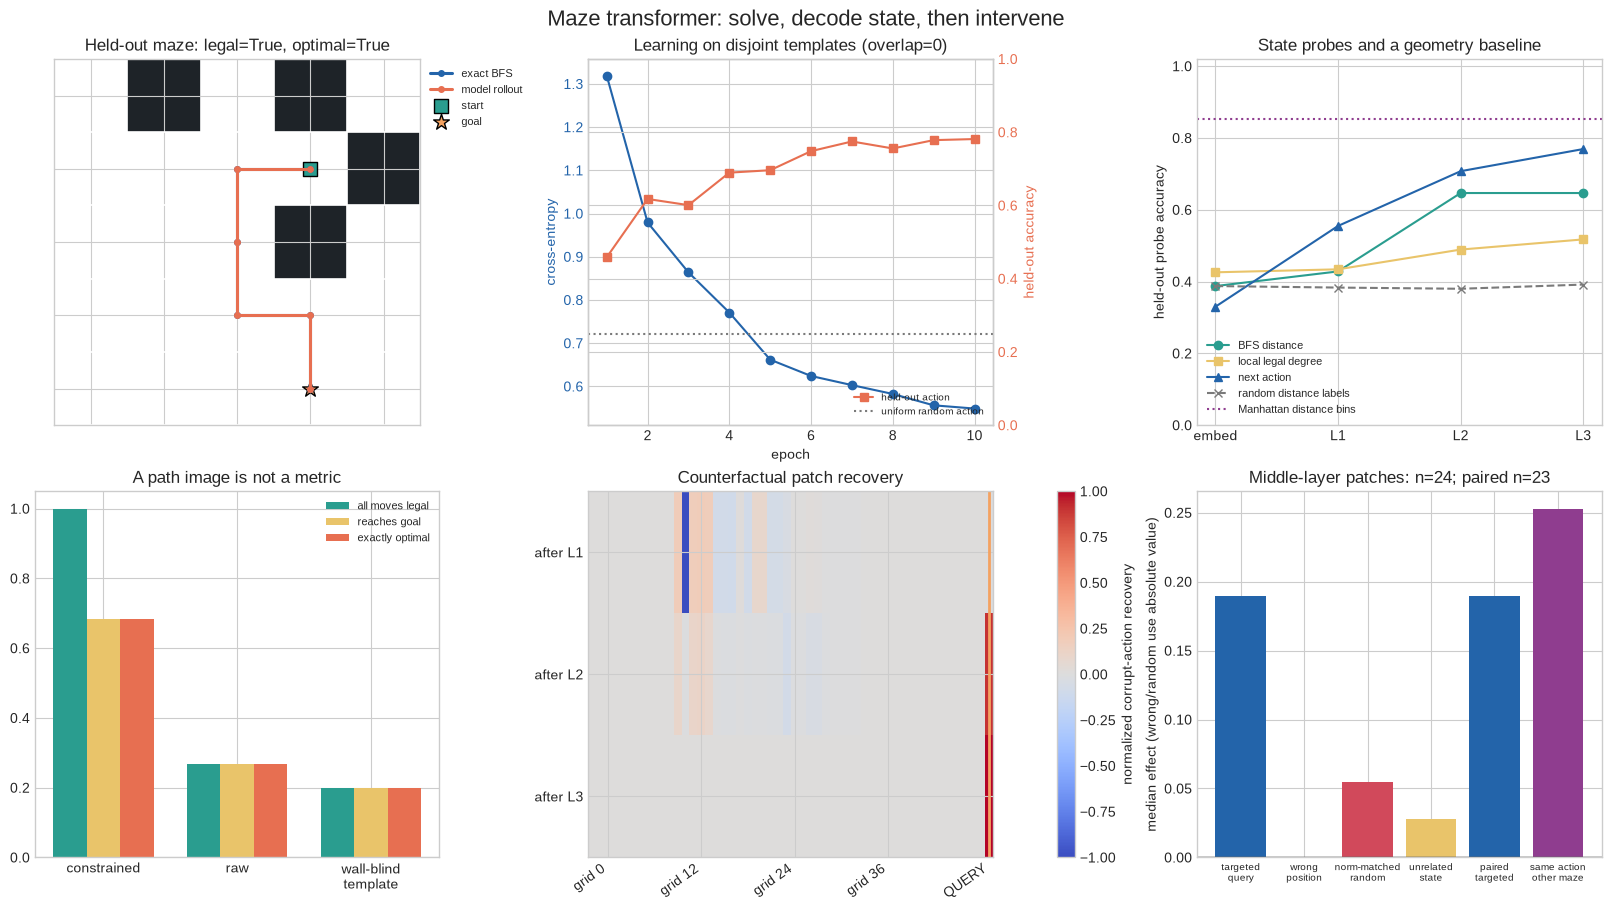

,metric,value
0,held-out action,0.781
1,detour action,0.599
2,shuffled-maze detour,0.503
3,constrained goal reach,0.683
4,raw goal reach,0.267
5,wall-blind template goal reach,0.200
6,density OOD goal reach,0.575
7,size-6 OOD goal reach,0.167


best distance probe: 0.647 vs random labels 0.392
targeted patch: 0.189 vs matched random 0.055
same-action donor: 0.253 vs paired targeted 0.189
Manhattan distance bins: 0.853
saved: /home/bitwise/Documents/ARENA_3.0_Extended/chapter14_jepa_world_models/instructions/assets/maze_transformer_signature_result.png


In [27]:
artifacts = run_signature_experiment(
    device="cpu",
    seed=0,
    train_maze_count=260,
    heldout_maze_count=70,
    epochs=10,
    d_model=56,
)
try:
    validate_experiment(artifacts)
    print("The original numerical thresholds passed; inspect the stronger controls below.")
except AssertionError as error:
    print(f"A numerical threshold failed: {error}. Keep the result visible and inspect the failure.")
metrics = artifacts.metrics

example_index = 0  # Fixed before inspecting outcomes; do not select a successful route.
example_maze = artifacts.heldout_mazes[example_index]
example_rollout = artifacts.model_rollouts[example_index]

figure = plt.figure(figsize=(16, 9), constrained_layout=True)
grid = figure.add_gridspec(2, 3)
path_axis = figure.add_subplot(grid[0, 0])
train_axis = figure.add_subplot(grid[0, 1])
probe_axis = figure.add_subplot(grid[0, 2])
path_metric_axis = figure.add_subplot(grid[1, 0])
patch_axis = figure.add_subplot(grid[1, 1])
control_axis = figure.add_subplot(grid[1, 2])

plot_maze(
    path_axis,
    example_maze,
    paths=(example_maze.path, example_rollout.cells),
    labels=("exact BFS", "model rollout"),
    title=f"Held-out maze: legal={example_rollout.legal}, optimal={example_rollout.optimal}",
)
path_axis.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))

epochs = np.arange(1, len(artifacts.training.train_loss) + 1)
train_axis.plot(epochs, artifacts.training.train_loss, marker="o", color="#2364aa", label="train CE")
train_axis.set_xlabel("epoch")
train_axis.set_ylabel("cross-entropy", color="#2364aa")
train_axis.tick_params(axis="y", labelcolor="#2364aa")
accuracy_axis = train_axis.twinx()
accuracy_axis.plot(epochs, artifacts.training.heldout_action_accuracy, marker="s", color="#e76f51", label="held-out action")
accuracy_axis.axhline(0.25, linestyle=":", color="#7a7a7a", label="uniform random action")
accuracy_axis.set_ylim(0, 1)
accuracy_axis.legend(fontsize=7, loc="lower right")
accuracy_axis.set_ylabel("held-out accuracy", color="#e76f51")
accuracy_axis.tick_params(axis="y", labelcolor="#e76f51")
train_axis.set_title(f"Learning on disjoint templates (overlap={metrics['train_heldout_template_overlap']})")

layer_names = ["embed", *[f"L{layer}" for layer in range(1, len(artifacts.probes.distance_accuracy))]]
probe_axis.plot(layer_names, artifacts.probes.distance_accuracy, marker="o", label="BFS distance", color="#2a9d8f")
probe_axis.plot(layer_names, artifacts.probes.legal_degree_accuracy, marker="s", label="local legal degree", color="#e9c46a")
probe_axis.plot(layer_names, artifacts.probes.action_accuracy, marker="^", label="next action", color="#2364aa")
probe_axis.plot(layer_names, artifacts.probes.random_label_distance_accuracy, marker="x", linestyle="--", label="random distance labels", color="#7a7a7a")
probe_axis.axhline(artifacts.probes.manhattan_distance_accuracy, color="#8f3d8f", linestyle=":", label="Manhattan distance bins")
probe_axis.set_ylim(0, 1.02)
probe_axis.set_ylabel("held-out probe accuracy")
probe_axis.set_title("State probes and a geometry baseline")
probe_axis.legend(fontsize=8)

conditions = ["constrained", "raw", "wall-blind\ntemplate"]
legal = [metrics["legal_path_rate"], 1 - metrics["raw_illegal_move_rate"], 1 - metrics["template_illegal_move_rate"]]
reach = [metrics["goal_reach_rate"], metrics["raw_goal_reach_rate"], metrics["template_goal_reach_rate"]]
optimal = [metrics["optimal_path_rate"], metrics["raw_optimal_path_rate"], metrics["template_optimal_path_rate"]]
x = np.arange(3); width = 0.25
path_metric_axis.bar(x - width, legal, width, label="all moves legal", color="#2a9d8f")
path_metric_axis.bar(x, reach, width, label="reaches goal", color="#e9c46a")
path_metric_axis.bar(x + width, optimal, width, label="exactly optimal", color="#e76f51")
path_metric_axis.set_xticks(x, conditions)
path_metric_axis.set_ylim(0, 1.05)
path_metric_axis.set_title("A path image is not a metric")
path_metric_axis.legend(fontsize=8)

image = patch_axis.imshow(
    artifacts.patching.heatmap,
    aspect="auto",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)
patch_axis.axvline(QUERY_POSITION, color="#f4a261", linewidth=2)
patch_axis.set_yticks(range(artifacts.model.n_layers), [f"after L{index + 1}" for index in range(artifacts.model.n_layers)])
patch_axis.set_xticks([2, 14, 26, 38, 51], ["grid 0", "grid 12", "grid 24", "grid 36", "QUERY"], rotation=35, ha="right")
patch_axis.set_title("Counterfactual patch recovery")
figure.colorbar(image, ax=patch_axis, label="normalized corrupt-action recovery")

control_names = ["targeted\nquery", "wrong\nposition", "norm-matched\nrandom", "unrelated\nstate", "paired\ntargeted", "same action\nother maze"]
control_values = [
    metrics["targeted_patch_effect"], metrics["wrong_position_patch_effect"],
    metrics["matched_norm_random_patch_effect"], metrics["unrelated_route_patch_effect"],
    metrics["same_action_targeted_patch_effect"], metrics["same_action_other_maze_patch_effect"],
]
control_axis.bar(control_names, control_values, color=["#2364aa", "#7a7a7a", "#d1495b", "#e9c46a", "#2364aa", "#8f3d8f"])
control_axis.tick_params(axis="x", labelsize=7)
control_axis.axhline(0, color="black", linewidth=1)
control_axis.set_ylabel("median effect (wrong/random use absolute value)")
control_axis.set_title(f"Middle-layer patches: n={metrics['patch_pair_count']}; paired n={metrics['same_action_patch_pair_count']}")

figure.suptitle("Maze transformer: solve, decode state, then intervene", fontsize=16)
signature_path = assets_dir / "maze_transformer_signature_result.png"
figure.savefig(signature_path, dpi=180, bbox_inches="tight")
plt.show()

summary_rows = [
    ("held-out action", metrics["heldout_action_accuracy"]),
    ("detour action", metrics["detour_action_accuracy"]),
    ("shuffled-maze detour", metrics["shuffled_maze_detour_accuracy"]),
    ("constrained goal reach", metrics["goal_reach_rate"]),
    ("raw goal reach", metrics["raw_goal_reach_rate"]),
    ("wall-blind template goal reach", metrics["template_goal_reach_rate"]),
    ("density OOD goal reach", metrics["density_ood_goal_reach_rate"]),
    ("size-6 OOD goal reach", metrics["size_ood_goal_reach_rate"]),
]
display(pd.DataFrame(summary_rows, columns=["metric", "value"]).style.format({"value": "{:.3f}"}))
print(f"best distance probe: {metrics['best_distance_probe_accuracy']:.3f} vs random labels {metrics['random_label_distance_probe_accuracy']:.3f}")
print(f"targeted patch: {metrics['targeted_patch_effect']:.3f} vs matched random {metrics['matched_norm_random_patch_effect']:.3f}")
print(f"same-action donor: {metrics['same_action_other_maze_patch_effect']:.3f} vs paired targeted {metrics['same_action_targeted_patch_effect']:.3f}")
print(f"Manhattan distance bins: {metrics['manhattan_distance_accuracy']:.3f}")
print(f"saved: {signature_path}")

<details>
<summary>Interpretation - how strong is the world-state claim?</summary>

The model is trained only to choose a BFS-downhill action. Held-out action accuracy and optimal constrained
rollouts establish behavior on unseen wall layouts. Distance and legal-degree probes show that useful state is
linearly available inside the query stream. Same-maze route-state patches then change the relative next-action
logits, while wrong-position and matched-random controls are much smaller.

Compare the paired same-action control before calling the intervention route-specific. If an activation from
another maze with the same next action works similarly, the result is compatible with transferring an action
preference. Also compare BFS distance probes with the explicit Manhattan baseline: easy distance bins need not
reveal a search computation.

In the checked CPU run, the policy reaches the goal on 41/60 mazes with legal-action constraints, versus 16/60
with raw argmax and 12/60 for the wall-blind template. All reached paths in this run happen to be shortest;
the scorer tests nonoptimal successes separately. The true-detour accuracy gap after shuffling walls is 0.096.

The stronger interpretation fails its controls: Manhattan distance bins score 0.853 versus the best learned
distance probe at 0.647. On 23 matched pairs, the same-action other-maze donor effect is 0.253 versus 0.189
for the targeted donor. These are descriptive results from one seed, with interventions selected on correctly
classified route states. They support usable next-action information, not a discovered internal search or a
route-specific representation.

</details>

<details>
<summary>Limitations - what remains unresolved?</summary>

Raw argmax still makes many illegal moves; constrained decoding supplies legality from the environment. Size-6
OOD transfer is weak because row/column positions that were padded walls during training become active. The
shuffled-maze detour gap is modest, and colorless 5 by 5 mazes are far simpler than natural planning or
language tasks. The final-query patch is exact by construction, so the scientific comparison uses a middle
layer.

The larger CUDA configuration (900 training layouts, 180 held-out layouts,
18 epochs, width 72) is evaluated separately against the original thresholds.
Before CUDA training, set `CUBLAS_WORKSPACE_CONFIG=:4096:8` in a fresh process;
the training function enables deterministic algorithms and highest float32
matrix precision. See PyTorch's [reproducibility guidance](https://docs.pytorch.org/docs/2.12/notes/randomness.html).
Its first 60 rollout layouts have a different
detour composition from the CPU cohort, so do not interpret the two configurations
as a controlled scaling comparison. The thresholds have not been weakened.

</details>

## Try It Yourself: Change the Maze, Decoder, and Intervention

Change `PLAY_SEED`, `PLAY_DENSITY`, and `CONSTRAIN_LEGAL`. Compare the rendered route with BFS before looking at the metrics. Then change `PATCH_LAYER` and `PATCH_POSITION`: patching the query should usually matter more than patching an early grid token at the same layer.

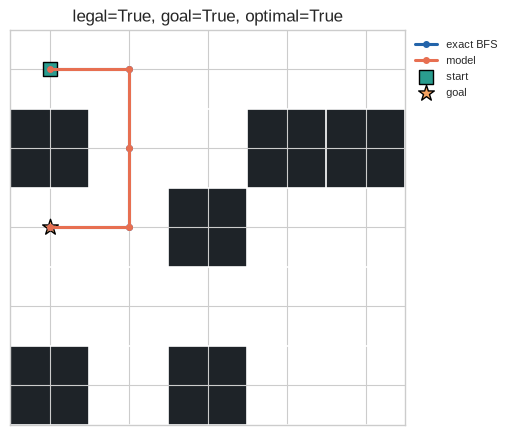

actions: ['right', 'down', 'down', 'left']


In [28]:
PLAY_SEED = 314
PLAY_DENSITY = 0.22
CONSTRAIN_LEGAL = True

play_maze = generate_maze(PLAY_SEED, obstacle_density=PLAY_DENSITY, require_detour=True)
play_rollout = rollout_model(artifacts.model, play_maze, constrain_legal=CONSTRAIN_LEGAL)
figure, axis = plt.subplots(figsize=(5, 4.5), constrained_layout=True)
plot_maze(
    axis,
    play_maze,
    paths=(play_maze.path, play_rollout.cells),
    labels=("exact BFS", "model"),
    title=f"legal={play_rollout.legal}, goal={play_rollout.reached_goal}, optimal={play_rollout.optimal}",
)
axis.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.show()
print("actions:", [ACTION_NAMES[action] for action in play_rollout.actions])

In [29]:
PATCH_LAYER = max(0, artifacts.model.n_layers - 2)
PATCH_POSITION = QUERY_POSITION
play_pair = _counterfactual_pairs(artifacts.model, artifacts.heldout_mazes, max_pairs=1)[0]
pair_maze, clean_index, corrupt_index = play_pair
device = next(artifacts.model.parameters()).device
clean_tokens = _state_tokens(pair_maze, pair_maze.path[clean_index], device)
corrupt_tokens = _state_tokens(pair_maze, pair_maze.path[corrupt_index], device)
clean_logits, _ = artifacts.model(clean_tokens, return_cache=True)
corrupt_logits, corrupt_cache = artifacts.model(corrupt_tokens, return_cache=True)
replacement = corrupt_cache["blocks"][PATCH_LAYER]["resid_post"][:, PATCH_POSITION]
patched_logits = artifacts.model(
    clean_tokens,
    residual_patch=(PATCH_LAYER, PATCH_POSITION, replacement),
)
probabilities = t.stack((clean_logits.softmax(-1)[0], corrupt_logits.softmax(-1)[0], patched_logits.softmax(-1)[0])).detach().cpu()
display(pd.DataFrame(probabilities.numpy(), index=["clean", "corrupt", "patched"], columns=ACTION_NAMES).style.format("{:.3f}"))

,up,right,down,left
clean,0.004,0.458,0.483,0.055
corrupt,0.003,0.661,0.317,0.018
patched,0.003,0.642,0.333,0.023


## Bonus: Anomaly Hunting

Choose one result that weakens the simple story and investigate it:

1. Why does raw decoding make illegal moves even when constrained optimality is strong?
2. Find a loop made only of legal moves. Which wrong action begins it?
3. Restrict evaluation to detour states. Does shuffling walls hurt more?
4. Compare distance probes at checkpoints. Does the probe rise before or after action accuracy?
5. Explain why patching the final QUERY residual recovers the corrupt logits exactly but says little about where planning happened.
6. Inspect size-6 failures. Which formerly padded positions became active?
7. Replace an unrelated route state with the same target action. Does its control effect increase?

Do not reroll seeds until the anomaly disappears. A failed generalization or control is information about the method's boundary.

## Reading and Research Directions

- [OthelloGPT: Emergent World Representations](https://arxiv.org/abs/2210.13382)
- [Structured World Representations in Maze-Solving Transformers](https://arxiv.org/abs/2312.02566). The paper
studies topology reconstruction and spatial structure. This lab uses dense next-action supervision and local
state probes; it does not reproduce the paper's full-maze reconstruction or adjacency-head analysis.
- Repeat with recurrent state-space models and compare where distance becomes decodable.
- Train on sizes 5 and 6, then test whether size 7 transfer becomes systematic.
- Replace linear probes with causal distance-direction interventions and test path changes.